# Question 1: Research Papers - Expert System

## 1.1 Loading and preprocessing the data

In [1]:
from pathlib import Path

PROJECT_DIR = Path.cwd().resolve()

ABSTRACTS_FILE = PROJECT_DIR / "research_abstracts.json"
CORPUS_FILE = PROJECT_DIR / "research_corpus.zip"
MODEL_FILE = PROJECT_DIR / "research_classifier.joblib"

Q3_OUTPUT_DIR = PROJECT_DIR / "question3_outputs"
Q4_OUTPUT_DIR = PROJECT_DIR / "question4_outputs"

print("Project directory:", PROJECT_DIR)
print("Abstracts dataset found:", ABSTRACTS_FILE.is_file())
print("Research corpus found:", CORPUS_FILE.is_file())
print("Saved model found:", MODEL_FILE.is_file())

Project directory: C:\Users\samir\Documents\ITNPA_Project
Abstracts dataset found: True
Research corpus found: True
Saved model found: True


In [2]:
import pandas as pd

df = pd.read_json(ABSTRACTS_FILE)

print("Dataset loaded successfully.")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()

Dataset loaded successfully.
Number of rows: 1138
Number of columns: 3


,DOI,Abstract,Label
0,10.1155/2021/1071145,Forward-looking forecasting of the inflation r...,ai
1,10.1007/s43546-022-00384-2,Our study examined the disaggregation of infla...,ai
2,10.1002/for.2667,This paper develops a dynamic factor model tha...,classical
3,10.1007/s42973-021-00091-x,"In this paper, I use a simple SIR Macro model ...",classical
4,10.1007/s40258-012-0003-z,BackgroundGame theory is useful for identifyin...,classical


## Inital data inspection

The JSON dataset we have loaded was successfully loaded into a pandas DataFrame with 1138 records and three columns: DOI, Abstract and Label. Research abstracts and categories are included in each record.

In [2]:
print("DATAFRAME INFORMATION")
df.info()

print("\nMISSING VALUES PER COLUMN")
print(df.isna().sum())

print("\nBLANK VALUES PER COLUMN")
for column in df.columns:
    blank_count = (
        df[column]
        .fillna("")
        .astype(str)
        .str.strip()
        .eq("")
        & df[column].notna()
    ).sum()

    print(f"{column}: {blank_count}")

print("\nDUPLICATE CHECKS")
print("Duplicate complete rows:", df.duplicated().sum())
print("Repeated abstracts:", df.duplicated(subset=["Abstract"]).sum())

print("\nCLASS DISTRIBUTION")
print(df["Label"].value_counts(dropna=False))

DATAFRAME INFORMATION
<class 'pandas.core.frame.DataFrame'>
Index: 1138 entries, 0 to 1137
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   DOI       1134 non-null   object
 1   Abstract  1138 non-null   object
 2   Label     1138 non-null   object
dtypes: object(3)
memory usage: 35.6+ KB

MISSING VALUES PER COLUMN
DOI         4
Abstract    0
Label       0
dtype: int64

BLANK VALUES PER COLUMN
DOI: 0
Abstract: 0
Label: 0

DUPLICATE CHECKS
Duplicate complete rows: 2
Repeated abstracts: 13

CLASS DISTRIBUTION
Label
classical    900
ai           238
Name: count, dtype: int64


## Data quality findings and preprocessing decisions

The dataset contains 1,138 records. The Abstract and Label columns have no missing or blank values. Four records have missing DOI values; these records are retained because their abstracts and category labels are available for classification.

There are two duplicate complete rows and 13 repeated abstracts. These counts overlap. Duplicate abstracts will be removed after text normalisation, as differences in capitalisation, punctuation or spacing may conceal additional duplicates.

The dataset is imbalanced, with 900 classical papers and 238 AI papers. 

In [3]:
import re
import html
import unicodedata

def clean_text(value):
    # Return empty text if the value is missing.
    if pd.isna(value):
        return ""

    # Decode HTML entities, such as &amp;, and normalise characters.
    text = html.unescape(str(value))
    text = unicodedata.normalize("NFKC", text)

    # Remove HTML tags.
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove web addresses.
    text = re.sub(
        r"https?://\S+|www\.\S+", " ", text, flags=re.IGNORECASE
    )

    # Remove email addresses.
    text = re.sub(
        r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b", " ", text
    )

    # Remove DOI identifiers appearing within the abstract.
    text = re.sub(
        r"\b10\.\d{4,9}/\S+", " ", text, flags=re.IGNORECASE
    )

    # Convert text to lowercase.
    text = text.lower()

    # Replace punctuation and symbols with spaces.
    # Preserve letters and digits.
    text = "".join(
        character
        if character.isalnum() or character.isspace()
        else " "
        for character in text
    )

    # Replace repeated whitespace with a single space.
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [4]:
# Work on a copy to preserve the original DataFrame.
df_clean = df.copy()

# Standardise category labels.
df_clean["Label"] = (
    df_clean["Label"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Create a cleaned version of each abstract.
df_clean["clean_abstract"] = df_clean["Abstract"].apply(clean_text)

# Show one complete abstract before and after cleaning.
print("ORIGINAL ABSTRACT:\n")
print(df_clean["Abstract"].iloc[0])

print("\nCLEANED ABSTRACT:\n")
print(df_clean["clean_abstract"].iloc[0])

# Check whether cleaning produced any empty abstracts.
print(
    "\nEmpty abstracts after cleaning:",
    df_clean["clean_abstract"].eq("").sum()
)

# Count repeated abstracts after normalisation.
print(
    "Repeated abstracts after cleaning:",
    df_clean.duplicated(subset=["clean_abstract"]).sum()
)

ORIGINAL ABSTRACT:

Forward-looking forecasting of the inflation rate could help the central bank and other government departments to better use monetary policy to stabilize prices and prevent the impact of inflation on market entities, especially for low- and middle-income groups. It can also help financial institutions and investors better make investment decisions. In this sense, the forecast of inflation rate is of great significance. The existing literature mainly uses linear models such as autoregressive (AR) and vector autoregressive (VAR) models to predict the inflation rate. The nonlinear relationship between variables and the mining of historical data information are relatively lacking. Therefore, the prediction strategies and accuracy of the existing literature need to be improved. The predictive model designed in deep learning can fully mine the nonlinear relationship between variables and process complex long-term time series dynamic information, thereby making up for the 

In [5]:
labels_per_abstract = (
    df_clean.groupby("clean_abstract")["Label"].nunique()
)

conflicting_abstracts = labels_per_abstract[
    labels_per_abstract > 1
].index

print(
    "Cleaned abstracts with conflicting labels:",
    len(conflicting_abstracts)
)

conflict_mask = df_clean["clean_abstract"].isin(
    conflicting_abstracts
)

print("Rows excluded for conflicting labels:", conflict_mask.sum())

df_clean = df_clean.loc[~conflict_mask].copy()

rows_before = len(df_clean)

df_clean = (
    df_clean
    .drop_duplicates(subset=["clean_abstract"], keep="first")
    .reset_index(drop=True)
)

print("Duplicate rows removed:", rows_before - len(df_clean))
print("Final number of records:", len(df_clean))

print("\nFINAL CLASS DISTRIBUTION")
print(df_clean["Label"].value_counts())

assert df_clean["clean_abstract"].ne("").all()
assert not df_clean["clean_abstract"].duplicated().any()

print("\nPreprocessing checks passed.")

Cleaned abstracts with conflicting labels: 0
Rows excluded for conflicting labels: 0
Duplicate rows removed: 17
Final number of records: 1121

FINAL CLASS DISTRIBUTION
Label
classical    886
ai           235
Name: count, dtype: Int64

Preprocessing checks passed.


## Text denoising results

The cleaning procedure standardised the abstracts by converting text to lowercase, replacing punctuation with spaces and normalising whitespace

No abstracts became empty after cleaning. The number of repeated abstracts increased from 13 to 17 after normalisation.

Before removing duplicates, identical cleaned abstracts are checked for conflicting category labels. Deduplication is performed before the training–test split to prevent identical text from appearing in both partitions and producing an overly optimistic evaluation.

No conflicting category labels were found among identical cleaned abstracts. Removing 17 duplicate abstracts reduced the dataset from 1,138 to 1,121 records, comprising 886 classical papers and 235 AI papers. The final checks confirmed that all cleaned abstracts were nonempty and unique. The four records with missing DOI values were retained because their abstracts and labels were available.

# 1.2 Feature selection and engineering

The cleaned abstracts will be transformed to numerical features using the TF-IDF (Term Frequency–Inverse Document Frequency) method. It places more importance on the terms that occur more often in a document and less often in the documents.

As stated previously, unigrams are individual words, bigrams are word pairs that are adjacent to each other such as “neural networks”. This is a representation of useful phrases and terms, but not full semantic understanding.

The data is split into training and test subsets prior to learning the vocabulary and IDF weights. This way, information from the test set doesn't drive feature engineering.

In [6]:
from sklearn.model_selection import train_test_split


X = df_clean["clean_abstract"]
y = df_clean["Label"]

# Reserve 20% for testing.
# Stratification preserves approximate category proportions.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training records:", len(X_train))
print("Test records:", len(X_test))

print("\nCLASS DISTRIBUTION BY PARTITION")
split_counts = pd.DataFrame({
    "Training": y_train.value_counts(),
    "Test": y_test.value_counts()
})

display(split_counts)

# Check that identical cleaned abstracts do not cross partitions.
assert set(X_train).isdisjoint(set(X_test))

print("\nNo identical cleaned abstracts occur in both partitions.")

Training records: 896
Test records: 225

CLASS DISTRIBUTION BY PARTITION


,Training,Test
Label,,
classical,708,178
ai,188,47



No identical cleaned abstracts occur in both partitions.


In [7]:
from sklearn.feature_extraction.text import (
    TfidfVectorizer,
    ENGLISH_STOP_WORDS
)

stop_words = sorted(
    set(ENGLISH_STOP_WORDS) - {"no", "nor", "not", "never"}
)
tfidf = TfidfVectorizer(
    stop_words=stop_words,
    ngram_range=(1, 2),
    min_df=2,
    max_features=10000,
    sublinear_tf=True,
    norm="l2"
)

X_train_tfidf = tfidf.fit_transform(X_train)

# Apply the learned transformation to the test data.
X_test_tfidf = tfidf.transform(X_test)

print("Training feature matrix:", X_train_tfidf.shape)
print("Test feature matrix:", X_test_tfidf.shape)
print("Number of features:", len(tfidf.get_feature_names_out()))

feature_names = tfidf.get_feature_names_out()
first_document = X_train_tfidf.getrow(0)

top_features = pd.DataFrame({
    "Feature": feature_names[first_document.indices],
    "TF-IDF weight": first_document.data
}).sort_values("TF-IDF weight", ascending=False).head(15)

print("\nFIRST TRAINING ABSTRACT (EXCERPT)")
print(X_train.iloc[0][:500])

print("\nTOP 15 FEATURES IN THIS ABSTRACT")
display(top_features.reset_index(drop=True))

Training feature matrix: (896, 10000)
Test feature matrix: (225, 10000)
Number of features: 10000

FIRST TRAINING ABSTRACT (EXCERPT)
the linear pool is the most popular method for combining density forecasts we analyze the linear pool s implications concerning forecast uncertainty in a new theoretical framework that focuses on the mean and variance of each density forecast to be combined our results show that if the variance predictions of the individual forecasts are unbiased the well known disagreement component of the linear pool exacerbates the upward bias of the linear pool s variance prediction moreover we find that dis

TOP 15 FEATURES IN THIS ABSTRACT


,Feature,TF-IDF weight
0,pool,0.357729
1,disagreement,0.254840
2,forecast uncertainty,0.213950
3,linear,0.210526
4,variance,0.196756
5,density,0.160943
6,component,0.156663
7,results variance,0.148032
8,upward bias,0.148032
9,post forecast,0.141676


The resulting training feature matrix has dimensions (896, 10000), and the test feature matrix has dimensions (225, 10000). Each row represents an abstract, and each column represents a learned unigram or bigram. Both partitions use the same training-derived vocabulary.

For the inspected training abstract, highly weighted features include “pool”, “disagreement” and “forecast uncertainty”, reflecting its discussion of combining density forecasts. This demonstrates that the representation captures individual terms and short phrases relevant to the document’s content.

## 1.3 Baseline model and performance evaluation

### Model selection

Logistic regression was selected as the baseline classifier because it is a relatively simple linear model suitable for high-dimensional, sparse TF-IDF features.

Since classical papers outnumber AI papers, balanced class weights are used to give greater weight to minority-class examples during training. A majority-class dummy classifier provides a reference benchmark by always predicting the most frequent training category.

Training performance measures the model’s fit to examples it has seen, while held-out test performance estimates generalisation to unseen examples from this dataset. Accuracy, balanced accuracy and macro-F1 are reported because accuracy alone can obscure poor minority-class performance.

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

baseline_model = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

baseline_model.fit(X_train_tfidf, y_train)

train_predictions = baseline_model.predict(X_train_tfidf)
test_predictions = baseline_model.predict(X_test_tfidf)

dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train_tfidf, y_train)

dummy_predictions = dummy_model.predict(X_test_tfidf)

def evaluate_predictions(actual, predicted):
    return {
        "Accuracy": accuracy_score(actual, predicted),
        "Balanced accuracy": balanced_accuracy_score(
            actual, predicted
        ),
        "Macro-F1": f1_score(
            actual,
            predicted,
            average="macro",
            zero_division=0
        )
    }

performance_table = pd.DataFrame({
    "Logistic regression — training": evaluate_predictions(
        y_train, train_predictions
    ),
    "Logistic regression — test": evaluate_predictions(
        y_test, test_predictions
    ),
    "Majority benchmark — test": evaluate_predictions(
        y_test, dummy_predictions
    )
}).T

display(performance_table.round(4))

,Accuracy,Balanced accuracy,Macro-F1
Logistic regression — training,0.9900,0.9917,0.9851
Logistic regression — test,0.9022,0.8521,0.8521
Majority benchmark — test,0.7911,0.5000,0.4417


### Initial performance interpretation

The logistic regression baseline had a training accuracy of 99.00% and a hold-out accuracy of 90.22%. It achieved the highest accuracy with 89.73% among 11 other models, which is 11.11 percentage points higher than the majority-class model accuracy of 79.11%.

The balanced accuracy was 0.8521 and the majority benchmark was 0.5000. The macro-F1 was also very high at 0.8521 compared to the benchmark's 0.4417. The results show that these algorithms are able to make more useful predictions than picking the most common class.

The macro-F1 in the test set, however, was 0.8521, which is lower than the training set's macro-F1 of 0.9851. There is some overfitting indicated by this training-test gap. There is a need for per class assessment to know if there is any difference between the performance of the AI papers and the classical papers.

HELD-OUT TEST CLASSIFICATION REPORT

              precision    recall  f1-score   support

          ai     0.7660    0.7660    0.7660        47
   classical     0.9382    0.9382    0.9382       178

    accuracy                         0.9022       225
   macro avg     0.8521    0.8521    0.8521       225
weighted avg     0.9022    0.9022    0.9022       225

CONFUSION MATRIX


,Predicted ai,Predicted classical
Actual ai,36,11
Actual classical,11,167


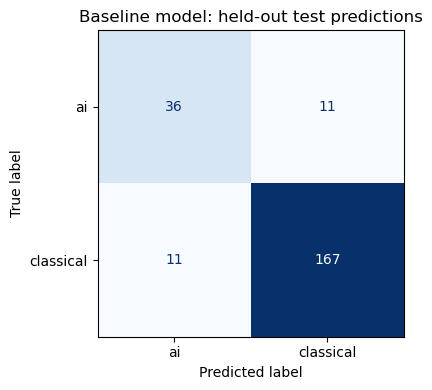

In [9]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

class_labels = ["ai", "classical"]

print("HELD-OUT TEST CLASSIFICATION REPORT\n")

print(
    classification_report(
        y_test,
        test_predictions,
        labels=class_labels,
        digits=4,
        zero_division=0
    )
)


cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=class_labels
)

print("CONFUSION MATRIX")

display(
    pd.DataFrame(
        cm,
        index=["Actual ai", "Actual classical"],
        columns=["Predicted ai", "Predicted classical"]
    )
)

fig, ax = plt.subplots(figsize=(6, 4))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_labels
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Baseline model: held-out test predictions")
plt.tight_layout()
plt.show()

### Reliability of per-class performance and error analysis.

For AI papers, the model obtained precision, recall and F1-score of 0.7660 while for classical papers the precision, recall and F1-score were 0.9382. This proves that the minority AI category has been underperforming the overall performance with 90.22% test accuracy.

The confusion matrix illustrates the correct classification of 36 AI papers and 167 classical papers. There were 11 AI papers that were mistakenly identified as classical, and 11 classical papers that were mistakenly identified as AI.

If the model is used by Researchly to filter AI research it may miss out on relevant literature. On the other hand, classical papers made an incorrect prediction of manual screening effort increasing as AI comes. Hence, the model is not intended to automatically reject papers, but rather to serve as a guide to help humans decide this.

In this test set the precision and recall are the same for every category due to the equal number of misclassifications of each type. This equality only holds true for these results and does not apply to the model in general.

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone

cv_pipeline = Pipeline([
    ("tfidf", clone(tfidf)),
    ("classifier", clone(baseline_model))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    cv_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "balanced_accuracy": "balanced_accuracy",
        "macro_f1": "f1_macro"
    },
    return_train_score=True
)

metric_names = ["accuracy", "balanced_accuracy", "macro_f1"]

cv_summary = pd.DataFrame({
    "Metric": metric_names,
    "Mean training score": [
        cv_results[f"train_{metric}"].mean()
        for metric in metric_names
    ],
    "Mean validation score": [
        cv_results[f"test_{metric}"].mean()
        for metric in metric_names
    ],
    "Validation standard deviation": [
        cv_results[f"test_{metric}"].std()
        for metric in metric_names
    ]
})

display(cv_summary.round(4))

,Metric,Mean training score,Mean validation score,Validation standard deviation
0,accuracy,0.9908,0.8951,0.0141
1,balanced_accuracy,0.9922,0.8222,0.0230
2,macro_f1,0.9863,0.8352,0.0217


### Cross-validation findings

The mean and balanced accuracy on the validation set using five-fold cross validation were 0.8951, and 0.8222, respectively, with the macro-F1 being 0.8352. The standard deviation of the validations were 0.0141, 0.0230 and 0.0217 for the corresponding folds, so there was some variability between folds.

The accuracy of the validation set was 89.51% and only slightly below the held out test accuracy of 90.22%. Similarly, the validation macro-F1 of 0.8352 was not too far off the test macro-F1 of 0.8521. This is further proof that one split is not enough to make the performance of the baseline entirely good.

Mean training macro-F1, however, was 0.9863 which was significantly greater than mean validation macro-F1 of 0.8352. In combination with the training–test gap, this implies that the model is overfitting, which means that it is doing better on documents it has been trained on, than on documents it has not seen.

### Overall model assessment

The TF-IDF logistic regression baseline model was found to be useful for predicting the test accuracy; 90.22% as compared with 79.11% for the majority-class baseline model. It also beat the benchmark in test macro-F1, scoring 0.8521 vs. 0.4417.

The performance was better in classical papers compared to AI papers. The model identified 36 of 47 AI papers achieving 76.60% AI recall, and 167 of 178 classical papers, resulting in 99.43% classical paper recall. The 11 papers missed by AI can be of special interest when skimming through literature for AI research, as potentially valuable papers might be overlooked.

Errors and training–validation gap make the baseline suitable as a starting point to help research screening, but it needs improvement and human verification.

The limitations and potential improvements are discussed below.The following are the limitations and possible improvements.

TF-IDF is not a comprehensive representation of context or meaning, but rather vocabulary and short phrases. Future work should include comparisons with alternative classifiers and semantic text representations and the baseline. A further independent test set would be required if the current test results have an effect on the further development and tuning of the parameters.

The same cleaned abstracts have been deleted, but there may be near duplicate or alternate versions of the same paper. Label quality is not independently verified and performance of this collection does not imply performance of future publications of the same kind or other types of research.

# Question 2

## 2.1 Comparison of ML models

1. Linear Support Vector Machine
2. Multinomial Naive Bayes
3. Complement Naive Bayes
4. Random Forest

In [11]:
print("Cleaned dataset:", df_clean.shape)
print("Training documents:", len(X_train))
print("Test documents:", len(X_test))

print("\nTRAINING CLASS COUNTS")
print(y_train.value_counts())

print("\nBASELINE CROSS-VALIDATION RESULTS")
display(cv_summary.round(4))

Cleaned dataset: (1121, 4)
Training documents: 896
Test documents: 225

TRAINING CLASS COUNTS
Label
classical    708
ai           188
Name: count, dtype: Int64

BASELINE CROSS-VALIDATION RESULTS


,Metric,Mean training score,Mean validation score,Validation standard deviation
0,accuracy,0.9908,0.8951,0.0141
1,balanced_accuracy,0.9922,0.8222,0.0230
2,macro_f1,0.9863,0.8352,0.0217


In [12]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic regression (baseline)": clone(baseline_model),

    "Linear SVM": LinearSVC(
        C=1.0,
        class_weight="balanced",
        max_iter=10000,
        random_state=42
    ),

    "Multinomial Naive Bayes": MultinomialNB(
        alpha=1.0
    ),

    "Complement Naive Bayes": ComplementNB(
        alpha=1.0
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_splits = list(cv_strategy.split(X_train, y_train))

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "macro_f1": "f1_macro"
}

comparison_rows = []
model_cv_results = {}

for model_name, classifier in models.items():
    print(f"Evaluating: {model_name}", flush=True)

    pipeline = Pipeline([
        ("tfidf", clone(tfidf)),
        ("classifier", clone(classifier))
    ])

    results = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv_splits,
        scoring=scoring,
        return_train_score=True,
        n_jobs=1,
        error_score="raise"
    )

    model_cv_results[model_name] = results

    comparison_rows.append({
        "Model": model_name,
        "Training macro-F1": results["train_macro_f1"].mean(),
        "Validation accuracy": results["test_accuracy"].mean(),
        "Validation balanced accuracy":
            results["test_balanced_accuracy"].mean(),
        "Validation macro-F1": results["test_macro_f1"].mean(),
        "Macro-F1 SD": results["test_macro_f1"].std()
    })

model_comparison = (
    pd.DataFrame(comparison_rows)
    .set_index("Model")
    .sort_values("Validation macro-F1", ascending=False)
)

# Calculate improvement relative to logistic regression.
baseline_cv_f1 = model_comparison.loc[
    "Logistic regression (baseline)",
    "Validation macro-F1"
]

model_comparison["Macro-F1 change vs baseline"] = (
    model_comparison["Validation macro-F1"] - baseline_cv_f1
)

print("\nMODEL COMPARISON")
display(model_comparison.round(4))

best_model_name = model_comparison.index[0]
print("\nHighest mean validation macro-F1:", best_model_name)

Evaluating: Logistic regression (baseline)
Evaluating: Linear SVM
Evaluating: Multinomial Naive Bayes
Evaluating: Complement Naive Bayes
Evaluating: Random Forest

MODEL COMPARISON


,Training macro-F1,Validation accuracy,Validation balanced accuracy,Validation macro-F1,Macro-F1 SD,Macro-F1 change vs baseline
Model,,,,,,
Linear SVM,0.9987,0.9096,0.8158,0.8479,0.0263,0.0127
Logistic regression (baseline),0.9863,0.8951,0.8222,0.8352,0.0217,0.0000
Random Forest,1.0000,0.8906,0.7475,0.7941,0.0428,-0.0411
Complement Naive Bayes,0.8918,0.8605,0.6678,0.7097,0.0313,-0.1255
Multinomial Naive Bayes,0.6617,0.8013,0.5267,0.4946,0.0171,-0.3406



Highest mean validation macro-F1: Linear SVM


### Model comparison findings

The highest mean validation macro-F1 of 0.8479 was obtained by linear SVM with an increase of 0.0127 from the baseline value of logistic regression (0.8352). The accuracy of the validation also rose from 89.51% to 90.96%. Hence, Linear SVM was chosen as the first candidate to be enhanced.

However, the balanced accuracy was 0.8158 which is slightly lower than logistic regression (0.8222). This indicates that not all metrics showed improvement. The macro-F1 improvement was small compared to fold variation and was not alone enough to be a statistically significant improvement.

The macro-F1 of both the training set and the validation set were both 1 for Random Forest, but the validation set had an F1 score of only 0.7941, which means there is a significant amount of overfitting. The validation macro-F1 for Complement Naive Bayes was 0.7097 while Multinomial Naive Bayes was 0.4946, which is still below the baseline.

The Multinomial Naive Bayes model reached an accuracy of 80.13% and a BAA of 0.5267, showing that although accuracy is good, it is not enough for this imbalanced dataset.

Linear SVM also had a significant training–validation gap: training macro-F1 score of 0.9987 vs. validation macro-F1 score of 0.8479. The further improvement will then explore regularisation and feature settings with training-only cross validation.

## 2.2 enhancement through hyperparameter tuning

In [13]:
from sklearn.model_selection import GridSearchCV

tuning_pipeline = Pipeline([
    ("tfidf", clone(tfidf)),
    ("classifier", clone(models["Linear SVM"]))
])

parameter_grid = {
    "classifier__C": [0.1, 0.5, 1.0, 2.0],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [2, 3]
}

grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=parameter_grid,
    scoring="f1_macro",
    cv=cv_splits,
    refit=True,
    return_train_score=True,
    n_jobs=1,
    verbose=1,
    error_score="raise"
)

grid_search.fit(X_train, y_train)

print("\nBEST PARAMETERS")
print(grid_search.best_params_)

original_svm_f1 = model_comparison.loc[
    "Linear SVM", "Validation macro-F1"
]

tuning_comparison = pd.DataFrame({
    "Configuration": [
        "Original Linear SVM",
        "Tuned Linear SVM"
    ],
    "Mean validation macro-F1": [
        original_svm_f1,
        grid_search.best_score_
    ]
})

print("\nBEFORE AND AFTER TUNING")
display(tuning_comparison.round(4))

print(
    "\nChange in validation macro-F1:",
    round(grid_search.best_score_ - original_svm_f1, 4)
)

search_results = pd.DataFrame(grid_search.cv_results_)

columns_to_show = [
    "param_classifier__C",
    "param_tfidf__ngram_range",
    "param_tfidf__min_df",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

print("\nTOP FIVE CONFIGURATIONS")
display(
    search_results
    .sort_values("rank_test_score")
    [columns_to_show]
    .head(5)
    .reset_index(drop=True)
)
best_pipeline = grid_search.best_estimator_

Fitting 5 folds for each of 16 candidates, totalling 80 fits

BEST PARAMETERS
{'classifier__C': 0.5, 'tfidf__min_df': 3, 'tfidf__ngram_range': (1, 2)}

BEFORE AND AFTER TUNING


,Configuration,Mean validation macro-F1
0,Original Linear SVM,0.8479
1,Tuned Linear SVM,0.8485



Change in validation macro-F1: 0.0005

TOP FIVE CONFIGURATIONS


,param_classifier__C,param_tfidf__ngram_range,param_tfidf__min_df,mean_train_score,mean_test_score,std_test_score,rank_test_score
0,0.5,"(1, 2)",3,0.998326,0.848462,0.028699,1
1,1.0,"(1, 2)",2,0.998743,0.847913,0.026344,2
2,2.0,"(1, 1)",3,0.998743,0.846077,0.026427,3
3,0.5,"(1, 2)",2,0.998324,0.845662,0.031758,4
4,0.5,"(1, 1)",2,0.998743,0.844845,0.031942,5


### Hyperparameter tuning results

The 16 configurations were tested on five-fold stratified cross validation using a grid search. SVM, Linear SVM was selected with `C=0.5`, TF-IDF unigrams and bigrams, and a minimum document frequency of three.

The selected configuration is similar to the original SVM, but uses stronger regularisation and removes terms occurring in only 2 of the training documents.

The absolute change (validation macro-F1) rose from 0.847913 to 0.848462, for an absolute gain of about 0.000549. This improvement is quite insignificant compared to the fold standard deviation of 0.028699 for the selected configuration. So the results show an improvement in the search criterion but not a statistically significant or practically significant improvement.

The train–val gap continued to be high for macro-F1 (0.998326). Furthermore, the validation score that was highest was used for selecting the configuration, which can be optimistic. Additional test evaluation should be conducted to further evaluate the selected model.

In [14]:
original_svm_pipeline = Pipeline([
    ("tfidf", clone(tfidf)),
    ("classifier", clone(models["Linear SVM"]))
])

original_svm_pipeline.fit(X_train, y_train)

original_svm_test_predictions = original_svm_pipeline.predict(
    X_test
)

tuned_svm_test_predictions = best_pipeline.predict(X_test)

baseline_test_predictions = baseline_model.predict(
    tfidf.transform(X_test)
)

test_comparison = pd.DataFrame({
    "Logistic regression baseline": evaluate_predictions(
        y_test, baseline_test_predictions
    ),
    "Original Linear SVM": evaluate_predictions(
        y_test, original_svm_test_predictions
    ),
    "Tuned Linear SVM": evaluate_predictions(
        y_test, tuned_svm_test_predictions
    )
}).T

print("HELD-OUT TEST COMPARISON")
display(test_comparison.round(4))

print("\nTUNED SVM CLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        tuned_svm_test_predictions,
        labels=["ai", "classical"],
        digits=4,
        zero_division=0
    )
)

tuned_cm = confusion_matrix(
    y_test,
    tuned_svm_test_predictions,
    labels=["ai", "classical"]
)

print("TUNED SVM CONFUSION MATRIX")
display(
    pd.DataFrame(
        tuned_cm,
        index=["Actual ai", "Actual classical"],
        columns=["Predicted ai", "Predicted classical"]
    )
)

test_f1_change = (
    test_comparison.loc["Tuned Linear SVM", "Macro-F1"]
    - test_comparison.loc["Original Linear SVM", "Macro-F1"]
)

print(
    "\nTest macro-F1 change from tuning:",
    round(test_f1_change, 4)
)

HELD-OUT TEST COMPARISON


,Accuracy,Balanced accuracy,Macro-F1
Logistic regression baseline,0.9022,0.8521,0.8521
Original Linear SVM,0.9156,0.8527,0.8669
Tuned Linear SVM,0.9156,0.8527,0.8669



TUNED SVM CLASSIFICATION REPORT
              precision    recall  f1-score   support

          ai     0.8333    0.7447    0.7865        47
   classical     0.9344    0.9607    0.9474       178

    accuracy                         0.9156       225
   macro avg     0.8839    0.8527    0.8669       225
weighted avg     0.9133    0.9156    0.9138       225

TUNED SVM CONFUSION MATRIX


,Predicted ai,Predicted classical
Actual ai,35,12
Actual classical,7,171



Test macro-F1 change from tuning: 0.0


### Test evaluation of the enhancement

Both the original and tuned Linear SVM achieved test accuracy of 91.56%, balanced accuracy of 0.8527 and macro-F1 of 0.8669. These results exceeded the logistic regression baseline’s accuracy of 90.22% and macro-F1 of 0.8521.

However, hyperparameter tuning produced no improvement in these held-out test metrics. Its small cross-validation gain therefore did not translate into a measurable test-set gain. The improvement over logistic regression is associated with the SVM configuration, rather than demonstrated additional benefit from tuning.

The tuned SVM correctly classified 35 AI papers and 171 classical papers. It missed 12 AI papers and incorrectly classified seven classical papers as AI. AI precision increased to 0.8333, but AI recall was 0.7447, slightly below the baseline’s 0.7660. Consequently, the higher overall macro-F1 comes with a trade-off between detecting relevant AI papers and reducing false AI predictions.


The tuned Linear SVM pipeline was selected according to the predefined training cross-validation macro-F1 criterion. It ranked highest during cross-validation and tied with the original SVM on the reported test metrics. This selection does not imply that tuning established superior generalisation.



## 2.3 Web interface deployment

In [15]:
from pathlib import Path
import joblib
import sklearn

project_folder = Path(
    "C:/Users/samir/Documents/ITNPA_Project"
)

if not project_folder.is_dir():
    raise FileNotFoundError(
        f"Project folder was not found: {project_folder}"
    )

model_path = project_folder / "research_classifier.joblib"

# Save the fitted pipeline and useful metadata.
model_bundle = {
    "pipeline": best_pipeline,
    "sklearn_version": sklearn.__version__,
    "input_type": "cleaned abstract text",
    "class_names": list(
        best_pipeline.named_steps["classifier"].classes_
    )
}

joblib.dump(model_bundle, model_path)

loaded_bundle = joblib.load(model_path)

sample_text = X_test.iloc[:1]

prediction_before = best_pipeline.predict(sample_text)
prediction_after = loaded_bundle["pipeline"].predict(sample_text)

assert (
    prediction_before == prediction_after
).all(), "The reloaded model produced a different prediction."

print("Model saved to:", model_path)
print("Scikit-learn version:", sklearn.__version__)
print("Classes:", loaded_bundle["class_names"])
print("Save-and-reload prediction check passed.")

Model saved to: C:\Users\samir\Documents\ITNPA_Project\research_classifier.joblib
Scikit-learn version: 1.7.2
Classes: ['ai', 'classical']
Save-and-reload prediction check passed.


In [16]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [17]:
import sys
import streamlit
import sklearn
from pathlib import Path

print("Python executable:", sys.executable)
print("Streamlit version:", streamlit.__version__)
print("Scikit-learn version:", sklearn.__version__)

model_path = Path(
    "C:/Users/samir/Documents/ITNPA_Project/"
    "research_classifier.joblib"
)

print("Saved model found:", model_path.is_file())

Python executable: C:\Users\samir\anaconda3\python.exe
Streamlit version: 1.51.0
Scikit-learn version: 1.7.2
Saved model found: True


In [18]:
%%writefile C:/Users/samir/Documents/ITNPA_Project/app.py
from pathlib import Path
import re
import html
import unicodedata

import joblib
import streamlit as st


st.set_page_config(
    page_title="Researchly Research Abstract Classifier",
    page_icon="📄",
    layout="centered"
)


def clean_text(value):
    """Apply the same text cleaning used during model development."""
    text = html.unescape(str(value))
    text = unicodedata.normalize("NFKC", text)

    text = re.sub(r"<[^>]+>", " ", text)

    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text,
        flags=re.IGNORECASE
    )

    text = re.sub(
        r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b",
        " ",
        text
    )

    text = re.sub(
        r"\b10\.\d{4,9}/\S+",
        " ",
        text,
        flags=re.IGNORECASE
    )

    text = text.lower()

    text = "".join(
        character
        if character.isalnum() or character.isspace()
        else " "
        for character in text
    )

    return re.sub(r"\s+", " ", text).strip()


@st.cache_resource
def load_pipeline():
    model_path = (
        Path(__file__).resolve().parent
        / "research_classifier.joblib"
    )

    bundle = joblib.load(model_path)
    return bundle["pipeline"]


st.title("Researchly Research Abstract Classifier")

st.write(
    "This app classifies research abstracts as either "
    "AI-related or classical research."
)

try:
    pipeline = load_pipeline()
except Exception as error:
    st.error(
        "The classifier could not be loaded. Check that "
        "research_classifier.joblib is in the same folder as app.py."
    )
    st.exception(error)
    st.stop()


with st.form("classification_form"):
    abstract = st.text_area(
        "Enter research abstract:",
        height=250,
        placeholder="Paste the research abstract here..."
    )

    submitted = st.form_submit_button("Classify Abstract")


if submitted:
    if not abstract.strip():
        st.warning("Please enter a research abstract.")
    else:
        cleaned_abstract = clean_text(abstract)

        if not cleaned_abstract:
            st.warning(
                "No usable text remains after cleaning. "
                "Please enter a research abstract containing words."
            )
        else:
    
            features = pipeline.named_steps["tfidf"].transform(
                [cleaned_abstract]
            )

            if features.nnz == 0:
                st.warning(
                    "The text contains no recognised model vocabulary. "
                    "Please provide a more complete research abstract."
                )
            else:
                prediction = pipeline.predict(
                    [cleaned_abstract]
                )[0]

                category_names = {
                    "ai": "artificial intelligence",
                    "classical": "classical research"
                }

                st.subheader("Prediction")
                st.success(
                    "The abstract is classified as: "
                    + category_names[prediction]
                )

st.caption(
    "Predictions support research screening and may be incorrect. "
    "Review the paper before deciding whether to include it."
)

Overwriting C:/Users/samir/Documents/ITNPA_Project/app.py


## 2.3 Deployment of the selected model in a web interface


### Selected model configuration

The tuned Linear Support Vector Machine (SVM) pipeline was selected because it achieved the highest mean cross-validation macro-F1 among the evaluated configurations.


### Conclusion

The selected TF-IDF and Linear SVM pipeline was successfully integrated into a working local Streamlit interface. Users can enter research abstracts, obtain category predictions and receive clear feedback for the tested invalid inputs. The implementation demonstrates how the classification model can support Researchly’s screening workflow while retaining human review.

# Question 3: Topic Analysis – Research Document Mining

## Creating the artical DataFrame

In [19]:
from pathlib import Path
import zipfile
import re
import pandas as pd

zip_path = Path(
    "C:/Users/samir/Documents/ITNPA_Project/research_corpus.zip"
)

if not zip_path.is_file():
    raise FileNotFoundError(
        f"Copy research_corpus.zip into your project folder: {zip_path.parent}"
    )

records = []

with zipfile.ZipFile(zip_path, "r") as archive:
    article_files = [
        name
        for name in archive.namelist()
        if re.fullmatch(
            r"research_\d+\.txt",
            Path(name).name,
            flags=re.IGNORECASE
        )
    ]
    article_files.sort(
        key=lambda name: int(
            re.search(r"research_(\d+)", Path(name).name).group(1)
        )
    )

    for name in article_files:
        content = archive.read(name).decode("utf-8")

        records.append({
            "article_id": int(
                re.search(r"research_(\d+)", Path(name).name).group(1)
            ),
            "filename": Path(name).name,
            "content": content,
            "character_count": len(content),
            "word_count": len(content.split())
        })

articles_df = pd.DataFrame(records)

assert len(articles_df) == 5, "Expected five articles."
assert articles_df["content"].str.strip().ne("").all(), (
    "At least one article is empty."
)

print("Number of articles loaded:", len(articles_df))

print("\nARTICLE INVENTORY")
display(
    articles_df[
        ["article_id", "filename", "character_count", "word_count"]
    ]
)

print("\nFIRST ARTICLE — FIRST 1,000 CHARACTERS")
print(articles_df.loc[0, "content"][:1000])

Number of articles loaded: 5

ARTICLE INVENTORY


,article_id,filename,character_count,word_count
0,1,research_1.txt,38598,5602
1,2,research_2.txt,16279,2416
2,3,research_3.txt,26521,3828
3,4,research_4.txt,39072,5922
4,5,research_5.txt,27142,4027



FIRST ARTICLE — FIRST 1,000 CHARACTERS
The purposes of this article are to position mixed methods research
(mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism
as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting
mixed methods research. In doing this, we briefly review the paradigm “wars” and incompatibility thesis, we show some commonalities between quantitative and qualitative research, we explain the
tenets of pragmatism, we explain the fundamental principle of mixed
research and how to apply it, we provide specific sets of designs for
the two major types of mixed methods research (mixed-model designs and mixed-method designs), and, finally, we explain mixed methods research as following (recursively) an eight-step process. A key
feature of mixed methods research is its methodological pluralism
or eclecticism, which frequently

### 3.1 Generating a DataFrame of research articles

The five research articles were read directly from `research_corpus.zip` and loaded into a pandas DataFrame named `articles_df`. Each row represents one article, identified by its article number and filename. The `content` column contains the complete original text of the corresponding article.

The files were sorted numerically from `research_1.txt` to `research_5.txt` to provide a consistent article order. Character counts and preliminary word counts were included as additional descriptive information. All five articles were loaded successfully and contained nonempty text.

### 3.2 Preprocessing the research articles

In [20]:
import re

inspection_rows = []

for _, row in articles_df.iterrows():
    text = row["content"]

    lines = text.replace("\r\n", "\n").replace("\r", "\n")

    inspection_rows.append({
        "filename": row["filename"],

        "URL occurrences": len(
            re.findall(r"https?://\S+|www\.\S+", text)
        ),

        "Replacement characters": text.count("\ufffd"),

        "Possible split words": len(
            re.findall(
                r"[A-Za-z]-[ \t]*\n+\s*[A-Za-z]",
                lines
            )
        ),

        "Reference headings": len(
            re.findall(
                r"(?im)^[ \t]*(?:references|bibliography|works cited)[ \t]*$",
                lines
            )
        )
    })

print("TEXT QUALITY INSPECTION")
display(pd.DataFrame(inspection_rows))


for _, row in articles_df.iterrows():
    print("\n" + "=" * 60)
    print("END OF:", row["filename"])
    print("=" * 60)
    print(row["content"][-1000:])

TEXT QUALITY INSPECTION


,filename,URL occurrences,Replacement characters,Possible split words,Reference headings
0,research_1.txt,0,0,0,0
1,research_2.txt,0,0,0,0
2,research_3.txt,0,0,0,0
3,research_4.txt,0,0,0,0
4,research_5.txt,0,0,0,0



END OF: research_1.txt
xed
methods research is currently in a position to provide perfect solutions. Mixed methods research should, instead (at this time),
use a method and philosophy that attempt to fit together the insights provided by qualitative and quantitative research into a
workable solution. Along these lines, we advocate consideration
of the pragmatic method of the classical pragmatists (e.g.,
Charles Sanders Peirce, William James, and John Dewey) as a
way for researchers to think about the traditional dualisms that
have been debated by the purists. Taking a pragmatic and balanced or pluralist position will help improve communication
among researchers from different paradigms as they attempt to
advance knowledge (Maxcy, 2003; Watson, 1990). Pragmatism
also helps to shed light on how research approaches can be mixed
fruitfully (Hoshmand, 2003); the bottom line is that research approaches should be mixed in ways that offer the best opportunities for answering important researc

### Findings and cleaning decisions

The inspection did not find any URLs, Unicode replacement characters, words that were split across line breaks or any stand-alone reference-section headings. Endings of the inspected texts do not consist of bibliographic lists but contain extensive discussion instead. Hence, there is no reference-section removal.

The second article seems to be "truncated" because its final sentence is cut off mid-sentence, mid-word. If there is text available, it is kept and nothing is made up. The content provided in this article was summarized in the content below and it may not represent the content of the article as it was originally written.

Initial cleaning will normalise Unicode characters, remove nonprinting formatting artefacts and standardise whitespace. Capitalisation, sentence punctuation, numbers, citations are kept to aid readable and faithful summaries, as are meaningful hyphens. The linguistic representation will then be created separately for Topic analysis.

In [21]:
import re
import unicodedata

def clean_article_text(text):
    text = unicodedata.normalize("NFKC", text)
    text = text.replace("\r\n", "\n").replace("\r", "\n")

   
    for character in ["\u200b", "\ufeff", "\u00ad"]:
        text = text.replace(character, "")

    text = "".join(
        " "
        if unicodedata.category(character) == "Cc"
        and character not in "\n\t"
        else character
        for character in text
    )


    text = re.sub(r"\s+", " ", text).strip()

    return text


articles_df["clean_content"] = articles_df["content"].apply(
    clean_article_text
)

articles_df["source_note"] = ""
articles_df.loc[
    articles_df["filename"] == "research_2.txt",
    "source_note"
] = "Appears truncated: supplied text ends mid-word."

articles_df["clean_character_count"] = (
    articles_df["clean_content"].str.len()
)

articles_df["clean_word_count"] = (
    articles_df["clean_content"].str.split().str.len()
)

assert articles_df["clean_content"].str.strip().ne("").all()

print("CLEANING SUMMARY")
display(
    articles_df[[
        "filename",
        "character_count",
        "clean_character_count",
        "word_count",
        "clean_word_count"
    ]]
)

print("\nORIGINAL EXCERPT — LINE BREAKS SHOWN")
print(repr(articles_df.loc[0, "content"][:600]))

print("\nCLEANED EXCERPT")
print(articles_df.loc[0, "clean_content"][:600])

print("\nSOURCE QUALITY NOTE")
display(
    articles_df.loc[
        articles_df["source_note"].ne(""),
        ["filename", "source_note"]
    ]
)

CLEANING SUMMARY


,filename,character_count,clean_character_count,word_count,clean_word_count
0,research_1.txt,38598,38159,5602,5602
1,research_2.txt,16279,16106,2416,2416
2,research_3.txt,26521,26120,3828,3811
3,research_4.txt,39072,38913,5922,5922
4,research_5.txt,27142,26832,4027,4027



ORIGINAL EXCERPT — LINE BREAKS SHOWN
'The purposes of this article are to position mixed methods research\r\n(mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism\r\nas offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting\r\nmixed methods research. In doing this, we briefly review the paradigm “wars” and incompatibility thesis, we show some commonalities between quantitative and qualitative research, we explain the\r\ntenets of pragmatism, we explain the fundamental principle of mixed\r\nr'

CLEANED EXCERPT
The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting 

,filename,source_note
1,research_2.txt,Appears truncated: supplied text ends mid-word.


In [22]:
from collections import Counter
import unicodedata

original = articles_df.loc[
    articles_df["filename"] == "research_3.txt",
    "content"
].iloc[0]

normalised = unicodedata.normalize("NFKC", original)

without_invisible = normalised
for character in ["\u200b", "\ufeff", "\u00ad"]:
    without_invisible = without_invisible.replace(character, "")

cleaned = clean_article_text(original)

print("WORD COUNTS AT EACH STAGE")
print("Original:", len(original.split()))
print("After Unicode normalisation:", len(normalised.split()))
print("After invisible-character removal:", len(without_invisible.split()))
print("After complete cleaning:", len(cleaned.split()))

print("\nNON-ASCII CHARACTERS IN THE ORIGINAL ARTICLE")

character_counts = Counter(
    character for character in original
    if ord(character) > 127
)

for character, count in character_counts.most_common():
    print(
        repr(character),
        f"U+{ord(character):04X}",
        unicodedata.name(character, "UNNAMED"),
        "Count:", count
    )

print("\nEXAMPLES OF WORDS CHANGED BY UNICODE NORMALISATION")

examples = []
for word in original.split():
    normalised_word = unicodedata.normalize("NFKC", word)

    if word != normalised_word:
        pair = (word, normalised_word)
        if pair not in examples:
            examples.append(pair)

for before, after in examples[:15]:
    print(repr(before), "->", repr(after))

WORD COUNTS AT EACH STAGE
Original: 3828
After Unicode normalisation: 3828
After invisible-character removal: 3828
After complete cleaning: 3811

NON-ASCII CHARACTERS IN THE ORIGINAL ARTICLE
'“' U+201C LEFT DOUBLE QUOTATION MARK Count: 27
'”' U+201D RIGHT DOUBLE QUOTATION MARK Count: 27
'’' U+2019 RIGHT SINGLE QUOTATION MARK Count: 22
'•' U+2022 BULLET Count: 4
'⇒' U+21D2 RIGHTWARDS DOUBLE ARROW Count: 4

EXAMPLES OF WORDS CHANGED BY UNICODE NORMALISATION


### Verification of the cleaning results

Cleaning reduced character counts in all five articles by removing unnecessary formatting and normalising whitespace. Word counts remained unchanged for four articles.

For `research_3.txt`, the whitespace-based count decreased from 3,828 to 3,811. Inspection of the source identified 17 standalone `U+0001` control characters at list-item positions. These formatting artefacts had been counted as words before cleaning. Their removal explains the decrease without indicating the deletion of 17 substantive words.

The readable cleaned text retains capitalisation, sentence punctuation, numbers and meaningful hyphens. The original content remains available for comparison.

In [23]:
%pip install spacy

Note: you may need to restart the kernel to use updated packages.


In [24]:
import sys
import subprocess

subprocess.check_call([
    sys.executable,
    "-m",
    "spacy",
    "download",
    "en_core_web_sm"
])

0

In [25]:
import spacy

nlp = spacy.load("en_core_web_sm", disable=["ner"])

print("spaCy version:", spacy.__version__)
print("Language model loaded successfully.")
print("Active components:", nlp.pipe_names)

example = nlp(
    "Researchers were comparing methods and analysing findings."
)

display(
    pd.DataFrame([
        {
            "Token": token.text,
            "Lemma": token.lemma_,
            "Part of speech": token.pos_,
            "Stop word": token.is_stop
        }
        for token in example
    ])
)

spaCy version: 3.8.18
Language model loaded successfully.
Active components: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer']


,Token,Lemma,Part of speech,Stop word
0,Researchers,researcher,NOUN,False
1,were,be,AUX,True
2,comparing,compare,VERB,False
3,methods,method,NOUN,False
4,and,and,CCONJ,True
5,analysing,analyse,VERB,False
6,findings,finding,NOUN,False
7,.,.,PUNCT,False


In [26]:
negation_words = {"no", "not", "nor", "never"}

def get_topic_tokens(doc):
    tokens = []

    for token in doc:
        
        if not token.is_alpha:
            continue

        lemma = token.lemma_.lower().strip()

        if (
            token.is_stop or nlp.vocab[lemma].is_stop
        ) and lemma not in negation_words:
            continue

        if len(lemma) < 2:
            continue

        tokens.append(lemma)

    return tokens


article_docs = list(
    nlp.pipe(articles_df["clean_content"].tolist(), batch_size=5)
)

articles_df["topic_tokens"] = [
    get_topic_tokens(doc) for doc in article_docs
]

articles_df["topic_text"] = articles_df["topic_tokens"].apply(
    " ".join
)

articles_df["topic_token_count"] = (
    articles_df["topic_tokens"].str.len()
)

articles_df["sentence_count"] = [
    sum(1 for sentence in doc.sents if sentence.text.strip())
    for doc in article_docs
]

assert articles_df["topic_token_count"].gt(0).all()
assert len(articles_df) == 5

print("LINGUISTIC PREPROCESSING SUMMARY")
display(
    articles_df[[
        "filename",
        "clean_word_count",
        "sentence_count",
        "topic_token_count"
    ]]
)

print("\nFIRST ARTICLE: READABLE CLEANED TEXT")
print(articles_df.loc[0, "clean_content"][:600])

print("\nFIRST ARTICLE: FIRST 50 TOPIC TOKENS")
print(articles_df.loc[0, "topic_tokens"][:50])

print("\nAll five articles have nonempty topic representations.")

LINGUISTIC PREPROCESSING SUMMARY


,filename,clean_word_count,sentence_count,topic_token_count
0,research_1.txt,5602,164,2950
1,research_2.txt,2416,64,1201
2,research_3.txt,3811,174,1988
3,research_4.txt,5922,191,3007
4,research_5.txt,4027,161,2114



FIRST ARTICLE: READABLE CLEANED TEXT
The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting mixed methods research. In doing this, we briefly review the paradigm “wars” and incompatibility thesis, we show some commonalities between quantitative and qualitative research, we explain the tenets of pragmatism, we explain the fundamental principle of mixed resear

FIRST ARTICLE: FIRST 50 TOPIC TOKENS
['purpose', 'article', 'position', 'mixed', 'method', 'research', 'mixed', 'research', 'synonym', 'natural', 'complement', 'traditional', 'qualitative', 'quantitative', 'research', 'present', 'pragmatism', 'offer', 'attractive', 'philosophical', 'partner', 'mixed', 'method', 'research', 'provide', 'framework', 'design', '

### Preprocessing results

Nonempty topic representations were present in all five articles. The number of topic tokens for five categories of articles were 2,950, 1,201, 1,988, 3,007, and 2,114 after the process of tokenisation, lemmatisation and filtering.

Important subject vocabulary is still available for analysis in the first article, as evidenced by the retention of words such as mixed, method, qualitative, quantitative and pragmatism.

Automatic sentence segmentation retrieved 164, 64, 174, 191 and 161 sentences in each of the following cases, respectively. These counts are approximate due to the possibility of headings, citations and abbreviations influencing the boundaries within sentences.

The original text and the cleaned and filtered topic representations have been retained separately. This enables both summarisation of the text that is readable and a numerical topic analysis. The lack of apparent truncation is still a limitation of the source data that does not benefit from any preprocessing.

### 3.3 Summarisation of the first article

In [27]:
first_article_index = articles_df.index[
    articles_df["filename"] == "research_1.txt"
][0]

first_article_doc = article_docs[first_article_index]

sentence_records = []

for sentence_number, sentence in enumerate(
    first_article_doc.sents,
    start=1
):
    sentence_text = sentence.text.strip()
    word_count = len(sentence_text.split())

    sentence_topic_text = " ".join(
        get_topic_tokens(sentence)
    )

    if word_count >= 10 and sentence_topic_text:
        sentence_records.append({
            "sentence_number": sentence_number,
            "sentence": sentence_text,
            "word_count": word_count,
            "topic_text": sentence_topic_text
        })

sentence_df = pd.DataFrame(sentence_records)

assert not sentence_df.empty, "No candidate sentences were found."

print("Article:", articles_df.loc[first_article_index, "filename"])
print("Candidate sentences:", len(sentence_df))

print("\nFIRST FIVE CANDIDATE SENTENCES")

for _, row in sentence_df.head(5).iterrows():
    print(
        f"\nSentence {row['sentence_number']} "
        f"({row['word_count']} words):"
    )
    print(row["sentence"])

print("\nCANDIDATE SENTENCE LENGTHS")
display(sentence_df["word_count"].describe().round(1))

Article: research_1.txt
Candidate sentences: 156

FIRST FIVE CANDIDATE SENTENCES

Sentence 1 (51 words):
The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting mixed methods research.

Sentence 2 (73 words):
In doing this, we briefly review the paradigm “wars” and incompatibility thesis, we show some commonalities between quantitative and qualitative research, we explain the tenets of pragmatism, we explain the fundamental principle of mixed research and how to apply it, we provide specific sets of designs for the two major types of mixed methods research (mixed-model designs and mixed-method designs), and, finally, we explain mixed methods research as following (recursively) an eight-step process.

Sentence 3 (23

count    156.0
mean      35.7
std       27.5
min       10.0
25%       22.0
50%       30.0
75%       39.0
max      235.0
Name: word_count, dtype: float64

In [28]:
repaired_sentences = []
buffer = ""
start_number = None

for sentence_number, sentence in enumerate(
    first_article_doc.sents,
    start=1
):
    text = sentence.text.strip()

    if not text:
        continue

    if not buffer:
        buffer = text
        start_number = sentence_number
    else:
        buffer += " " + text

    open_parenthesis = buffer.count("(") > buffer.count(")")
    open_square_bracket = buffer.count("[") > buffer.count("]")

    if not open_parenthesis and not open_square_bracket:
        repaired_sentences.append({
            "sentence_number": start_number,
            "sentence": buffer
        })
        buffer = ""
        start_number = None

if buffer:
    repaired_sentences.append({
        "sentence_number": start_number,
        "sentence": buffer
    })

repaired_docs = list(
    nlp.pipe(
        [item["sentence"] for item in repaired_sentences]
    )
)

sentence_records = []

for item, doc in zip(repaired_sentences, repaired_docs):
    word_count = len(item["sentence"].split())
    topic_text = " ".join(get_topic_tokens(doc))

    if word_count >= 10 and topic_text:
        sentence_records.append({
            "sentence_number": item["sentence_number"],
            "sentence": item["sentence"],
            "word_count": word_count,
            "topic_text": topic_text
        })

sentence_df = pd.DataFrame(sentence_records)

print("Candidate sentences after boundary repair:", len(sentence_df))

print("\nREPAIRED CANDIDATE BEGINNING AT SENTENCE 5")
for text in sentence_df.loc[
    sentence_df["sentence_number"] == 5, "sentence"
]:
    print(text)

print("\nTHREE LONGEST CANDIDATES")
for _, row in sentence_df.nlargest(3, "word_count").iterrows():
    print(
        f"\nSentence {row['sentence_number']} "
        f"({row['word_count']} words):"
    )
    print(row["sentence"])

Candidate sentences after boundary repair: 154

REPAIRED CANDIDATE BEGINNING AT SENTENCE 5
For more than a century, the advocates of quantitative and qualitative research paradigms have engaged in ardent dispute.1 From these debates, purists have emerged on both sides (cf. Campbell & Stanley, 1963; Lincoln & Guba, 1985).2 Quantitative purists (Ayer, 1959; Maxwell & Delaney, 2004; Popper, 1959; Schrag, 1992) articulate assumptions that are consistent with what is commonly called a positivist philosophy.3, 4 That is, quantitative purists believe that social observations should be treated as entities in much the same way that physical scientists treat physical phenomena.

THREE LONGEST CANDIDATES

Sentence 76 (235 words):
Basic agreement has been reached on each of the following issues: (a) the relativity of the “light of reason” (i.e., what appears reasonable can vary across persons); (b) theory-laden perception or the theory-ladenness of facts (i.e., what we notice and observe is affect

In [29]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

summary_candidates = sentence_df.copy()

summary_candidates["duplicate_key"] = (
    summary_candidates["sentence"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

before = len(summary_candidates)

summary_candidates = (
    summary_candidates
    .drop_duplicates(subset="duplicate_key", keep="first")
    .reset_index(drop=True)
)

print(
    "Duplicate candidate passages removed:",
    before - len(summary_candidates)
)

summary_vectorizer = TfidfVectorizer(
    lowercase=False,
    min_df=1,
    norm="l2"
)

sentence_matrix = summary_vectorizer.fit_transform(
    summary_candidates["topic_text"]
)

centroid = np.asarray(sentence_matrix.mean(axis=0))

centrality = cosine_similarity(
    sentence_matrix, centroid
).ravel()

pairwise_similarity = cosine_similarity(sentence_matrix)

summary_candidates["centrality"] = centrality

WORD_BUDGET = 250
MAX_PASSAGES = 6
RELEVANCE_WEIGHT = 0.7

selected_indices = []
selection_records = []
words_used = 0

while len(selected_indices) < MAX_PASSAGES:
    eligible = [
        i for i in range(len(summary_candidates))
        if i not in selected_indices
        and words_used + summary_candidates.loc[i, "word_count"]
        <= WORD_BUDGET
    ]

    if not eligible:
        break

    def mmr_score(i):
        redundancy = (
            pairwise_similarity[i, selected_indices].max()
            if selected_indices
            else 0.0
        )

        return (
            RELEVANCE_WEIGHT * centrality[i]
            - (1 - RELEVANCE_WEIGHT) * redundancy
        )

    best_index = max(eligible, key=mmr_score)

    selection_records.append({
        "Selection order": len(selected_indices) + 1,
        "Source passage": int(
            summary_candidates.loc[best_index, "sentence_number"]
        ),
        "Words": int(
            summary_candidates.loc[best_index, "word_count"]
        ),
        "Centrality": centrality[best_index],
        "MMR at selection": mmr_score(best_index)
    })

    selected_indices.append(best_index)
    words_used += int(
        summary_candidates.loc[best_index, "word_count"]
    )

assert selected_indices, "No passages fitted the summary budget."

selected_passages = (
    summary_candidates.loc[selected_indices]
    .sort_values("sentence_number")
)

first_article_summary = "\n\n".join(
    selected_passages["sentence"]
)

print("\nEXTRACTIVE SUMMARY\n")
print(first_article_summary)

original_word_count = len(
    articles_df.loc[first_article_index, "clean_content"].split()
)
summary_word_count = len(first_article_summary.split())

print("\nSUMMARY STATISTICS")
print("Unique candidate passages:", len(summary_candidates))
print("Selected passages:", len(selected_passages))
print("Summary words:", summary_word_count)
print(
    "Summary length as a percentage of cleaned article:",
    f"{100 * summary_word_count / original_word_count:.2f}%"
)

print("\nSELECTION DETAILS")
display(pd.DataFrame(selection_records).round(4))

Duplicate candidate passages removed: 77

EXTRACTIVE SUMMARY

The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting mixed methods research.

Both sets of purists view their paradigms as the ideal for research, and, implicitly if not explicitly, they advocate the incompatibility thesis (Howe, 1988), which posits that qualitative and quantitative research paradigms, including their associated methods, cannot and should not be mixed.

We hope the field will move beyond quantitative versus qualitative research arguments because, as recognized by mixed methods research, both quantitative and qualitative research are important and useful.

Mixed methods research as the third research paradigm can also help bridge the s

,Selection order,Source passage,Words,Centrality,MMR at selection
0,1,1,51,0.4686,0.3280
1,2,48,21,0.3902,0.2285
2,3,30,23,0.4358,0.2146
3,4,24,28,0.4141,0.1990
4,5,16,42,0.3726,0.1974
5,6,50,18,0.3692,0.1836


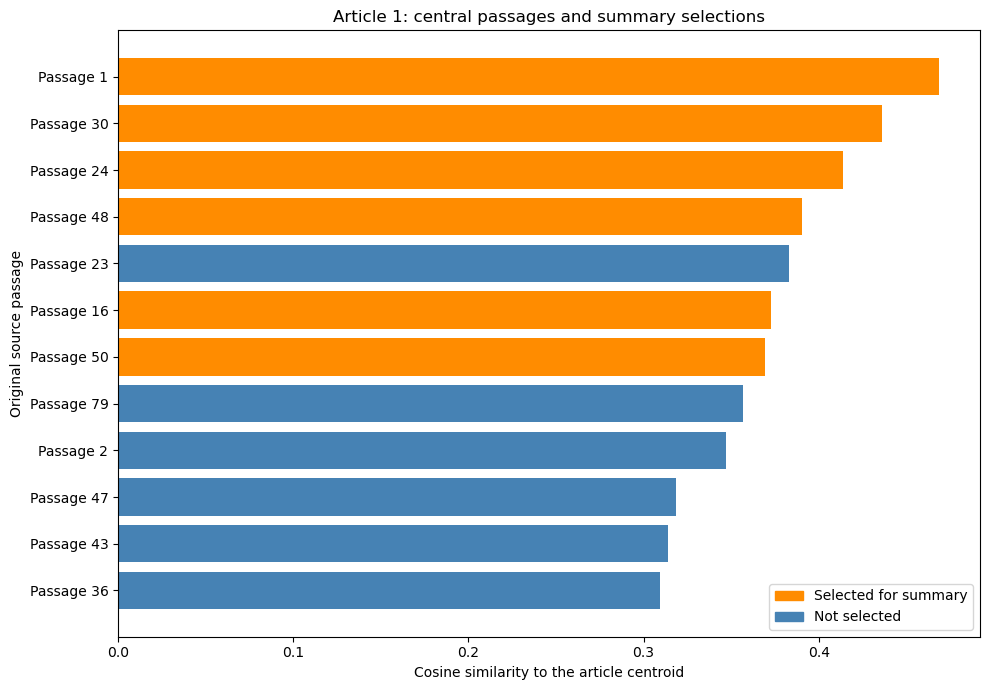

In [30]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

top_indices = (
    summary_candidates.nlargest(12, "centrality").index.tolist()
)

plot_indices = list(dict.fromkeys(
    top_indices + selected_indices
))

plot_data = (
    summary_candidates.loc[plot_indices]
    .sort_values("centrality")
)

colours = [
    "darkorange" if i in selected_indices else "steelblue"
    for i in plot_data.index
]

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    [
        f"Passage {int(number)}"
        for number in plot_data["sentence_number"]
    ],
    plot_data["centrality"],
    color=colours
)

ax.set_xlabel("Cosine similarity to the article centroid")
ax.set_ylabel("Original source passage")
ax.set_title("Article 1: central passages and summary selections")

ax.legend(handles=[
    Patch(color="darkorange", label="Selected for summary"),
    Patch(color="steelblue", label="Not selected")
])

plt.tight_layout()
plt.show()

In [31]:
from pathlib import Path

q3_output_folder = Path(
    "C:/Users/samir/Documents/ITNPA_Project/question3_outputs"
)
q3_output_folder.mkdir(parents=True, exist_ok=True)

(q3_output_folder / "article_1_summary.txt").write_text(
    first_article_summary,
    encoding="utf-8"
)

fig.savefig(
    q3_output_folder / "article_1_summary_scores.png",
    dpi=300,
    bbox_inches="tight"
)

pd.DataFrame(selection_records).to_csv(
    q3_output_folder / "article_1_selection_details.csv",
    index=False
)

print("Summary, chart and selection details saved to:")
print(q3_output_folder)

Summary, chart and selection details saved to:
C:\Users\samir\Documents\ITNPA_Project\question3_outputs


### Summarisation results

The number of candidate passages was 154 after sentence-boundary repair and minimum-length filtering. After eliminating 77 duplicate candidates, 77 unique passages were left for scoring. When creating the article's average TF-IDF representation, the same passages were not counted more than once because of the duplications that were prevented.

The extractive summariser came up with six passages that included a total of 183 words. This accounts for about 3.27% of the total cleaned source text of length 5,602 words. The six selected passages were all the passages available, so the summary did not exceed the budget of 250 words. The percentage is based on the complete cleaned source, but still includes repeated material.

The summary states that mixed-methods research is used in conjunction with qualitative and quantitative research, introduces the use of pragmatism as a supporting philosophy, outlines the incompatibility thesis and explains how mixed methods can be used to resolve methodological dichotomies.

The image is a representation of a learning environment.The image depicts a learning environment.

The horizontal bar chart shows the cosine similarity of candidate passages to the mean TFIDF vector of the article. Passages highlighted in orange are selected passages for the summary, and those highlighted in blue are displayed passages that are not selected.

The first one, Passage 1, was selected due to its highest centrality score, around 0.4686. It describes the purposes of the article, introduces mixed methods, pragmatism and research design.

The selection was not made solely on the basis of centrality. Balanced centrality vs similarity to already selected passages: maximal marginal relevance. Some passages selected were more central than passage 23, for example. Budget and passage rate were other selection restrictions.

This indicates the similarity of text within this article, not the probability or confidence score or the factual accuracy.

Qualitative assessment is performed on a case-by-case basis.Qualitative assessment is carried out on a case-by-case basis.

The produced summary shows the main position of the article in the direction of trying a combination of qualitative/quantitative methods. The approach produces passages from the source directly, enabling the selection to be tracked back to the article.

However, some highlighted sections make similar points regarding the fusion of research methods. The redundancy penalty thus lowered the selection only in terms of centrality, but didn't remove all conceptual repetition.

The summary notes that there is a design framework and pragmatism, but doesn't elaborate on them. It should, therefore, be viewed as an abridged summary of the article, rather than a full report on it. The expression “Both sets of purists” is partly also dependent on information that is not included in the extract, as it is context dependent: a coherence problem of extractive summarisation.

The repaired candidates do not consist of sentences that are clearly divided, but rather of sentence segments. Moreover, no reference summary was provided, thus the quality of the summaries was evaluated not by means of reference based evaluation measures but rather qualitatively.

## 3.4 Aggregate summarisation of the remaining articles

In [32]:
remaining_df = (
    articles_df.loc[
        articles_df["filename"] != "research_1.txt"
    ]
    .copy()
    .reset_index(drop=True)
)

assert len(remaining_df) == 4

docs_by_filename = dict(
    zip(articles_df["filename"], article_docs)
)

unique_texts = []
duplicate_counts = []

for filename in remaining_df["filename"]:
    doc = docs_by_filename[filename]

    seen = set()
    unique_passages = []
    duplicates = 0

    for sentence in doc.sents:
        text = sentence.text.strip()

        if not text:
            continue

        key = " ".join(text.lower().split())

        if key in seen:
            duplicates += 1
        else:
            seen.add(key)
            unique_passages.append(text)

    unique_texts.append(" ".join(unique_passages))
    duplicate_counts.append(duplicates)

remaining_df["modelling_content"] = unique_texts
remaining_df["duplicate_passages_removed"] = duplicate_counts

remaining_docs = list(
    nlp.pipe(remaining_df["modelling_content"], batch_size=4)
)

remaining_df["aggregate_tokens"] = [
    get_topic_tokens(doc) for doc in remaining_docs
]

remaining_df["aggregate_topic_text"] = (
    remaining_df["aggregate_tokens"].apply(" ".join)
)

remaining_df["aggregate_token_count"] = (
    remaining_df["aggregate_tokens"].str.len()
)

assert remaining_df["aggregate_token_count"].gt(0).all()

print("ARTICLES INCLUDED IN THE AGGREGATE ANALYSIS")
display(
    remaining_df[[
        "filename",
        "duplicate_passages_removed",
        "aggregate_token_count",
        "source_note"
    ]]
)

ARTICLES INCLUDED IN THE AGGREGATE ANALYSIS


,filename,duplicate_passages_removed,aggregate_token_count,source_note
0,research_2.txt,0,1201,Appears truncated: supplied text ends mid-word.
1,research_3.txt,0,1988,
2,research_4.txt,0,3007,
3,research_5.txt,0,2114,


In [33]:
from sklearn.feature_extraction.text import TfidfVectorizer

aggregate_vectorizer = TfidfVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    preprocessor=None,
    lowercase=False,
    ngram_range=(1, 1),
    min_df=1,
    max_df=1.0,
    max_features=2000,
    sublinear_tf=True,
    norm="l2"
)

aggregate_matrix = aggregate_vectorizer.fit_transform(
    remaining_df["aggregate_topic_text"]
)

print("Document–term matrix shape:", aggregate_matrix.shape)
print("Number of documents:", aggregate_matrix.shape[0])
print("Number of term features:", aggregate_matrix.shape[1])

print("\nExample vocabulary terms:")
print(aggregate_vectorizer.get_feature_names_out()[:30])

Document–term matrix shape: (4, 1943)
Number of documents: 4
Number of term features: 1943

Example vocabulary terms:
['aastrup' 'abbreviate' 'ability' 'able' 'abraham' 'absence' 'absent'
 'abstract' 'abused' 'academic' 'accent' 'accept' 'acceptability'
 'acceptable' 'acceptance' 'access' 'accessible' 'accidental' 'accomplish'
 'accord' 'account' 'accuracy' 'accurate' 'achieve' 'achievement' 'acid'
 'acknowledgement' 'act' 'action' 'active']


In [40]:
import numpy as np
from sklearn.decomposition import NMF

N_TOPICS = 3

nmf_model = NMF(
    n_components=N_TOPICS,
    init="nndsvda",
    random_state=42,
    max_iter=1000
)

document_topic_weights = nmf_model.fit_transform(
    aggregate_matrix
)

topic_term_weights = nmf_model.components_

topic_names = [
    f"Topic {number + 1}" for number in range(N_TOPICS)
]

feature_names = aggregate_vectorizer.get_feature_names_out()

print("NMF iterations:", nmf_model.n_iter_)
print(
    "Reconstruction error:",
    round(nmf_model.reconstruction_err_, 4)
)

topic_rows = []

for topic_index, weights in enumerate(topic_term_weights):
    top_indices = weights.argsort()[::-1][:12]

    topic_rows.append({
        "Topic": topic_names[topic_index],
        "Top terms": ", ".join(feature_names[top_indices])
    })

print("\nTOP TERMS PER TOPIC")
display(pd.DataFrame(topic_rows))

print("\nDOCUMENT–TOPIC WEIGHTS")
display(
    pd.DataFrame(
        document_topic_weights,
        index=remaining_df["filename"],
        columns=topic_names
    ).round(4)
)

component_sizes = topic_term_weights.sum(axis=1)

topic_contributions = (
    document_topic_weights * component_sizes
)

relative_topic_weights = (
    topic_contributions
    / topic_contributions.sum(axis=1, keepdims=True)
)

print("\nRELATIVE TOPIC CONTRIBUTIONS (%)")
display(
    pd.DataFrame(
        relative_topic_weights * 100,
        index=remaining_df["filename"],
        columns=topic_names
    ).round(1)
)

NMF iterations: 30
Reconstruction error: 0.8779

TOP TERMS PER TOPIC


,Topic,Top terms
0,Topic 1,"student, reliability, instrument, alpha, valid..."
1,Topic 2,"reflexivity, woman, immigrant, immigration, sh..."
2,Topic 3,"developmental, instructional, development, sys..."



DOCUMENT–TOPIC WEIGHTS


,Topic 1,Topic 2,Topic 3
filename,,,
research_2.txt,0.0000,0.7938,0.0000
research_3.txt,0.0000,0.0000,0.8578
research_4.txt,0.5618,0.0000,0.0126
research_5.txt,0.5091,0.0708,0.0000



RELATIVE TOPIC CONTRIBUTIONS (%)


,Topic 1,Topic 2,Topic 3
filename,,,
research_2.txt,0.0,100.0,0.0
research_3.txt,0.0,0.0,100.0
research_4.txt,98.6,0.0,1.4
research_5.txt,91.6,8.4,0.0


In [41]:
evidence_records = []

for filename, doc in zip(
    remaining_df["filename"],
    remaining_docs
):
    for sentence_number, sentence in enumerate(
        doc.sents, start=1
    ):
        text = sentence.text.strip()
        words = len(text.split())

        
        if 15 <= words <= 120:
            topic_text = " ".join(get_topic_tokens(sentence))

            if topic_text:
                evidence_records.append({
                    "filename": filename,
                    "sentence_number": sentence_number,
                    "passage": text,
                    "topic_text": topic_text
                })

evidence_df = pd.DataFrame(evidence_records)

assert not evidence_df.empty, "No evidence passages were found."

evidence_matrix = aggregate_vectorizer.transform(
    evidence_df["topic_text"]
)

evidence_topic_weights = nmf_model.transform(evidence_matrix)

for topic_index, topic_name in enumerate(topic_names):
    scores = evidence_topic_weights[:, topic_index]
    best_indices = np.argsort(scores)[::-1][:3]

    print("\n" + "=" * 65)
    print(topic_name.upper(), "— REPRESENTATIVE SOURCE PASSAGES")
    print("=" * 65)

    for index in best_indices:
        row = evidence_df.iloc[index]

        print(
            f"\n{row['filename']} | "
            f"Passage {row['sentence_number']} | "
            f"Topic weight: {scores[index]:.4f}"
        )
        print(row["passage"])


TOPIC 1 — REPRESENTATIVE SOURCE PASSAGES

research_4.txt | Passage 83 | Topic weight: 0.1802
Most (44/64) of the articles reporting results including alpha values did refer to alpha as reliability—including one exploring perceptions related to global warming that suggested it should not necessarily be seen a measure of internal consistency as “while Cronbach’s alphas are the standard value reported for scale reliability, this value tends to underestimate the internal consistency of scales consisting of fewer than 10 items” (Herman, 2015, p. 8) and offered mean inter-item correlation values as an alternative measure of internal consistency.

research_4.txt | Passage 95 | Topic weight: 0.1790
Many, but not all, of the papers found to cite alpha values in the 2015 volumes of four science education journals (IJSE, JRST, RISE, SE) offered qualitative interpretations of the significance of the values calculated in relation to what was being measured (which, as discussed above, was usually c

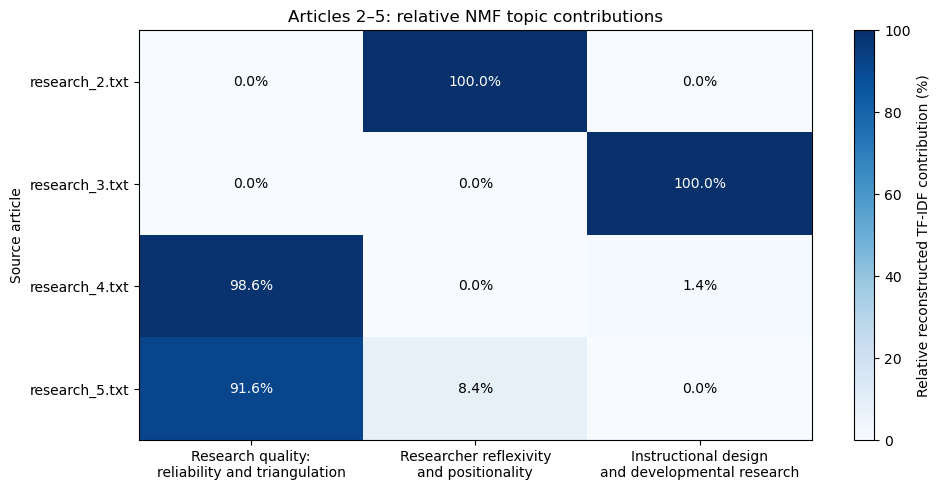

In [42]:
import matplotlib.pyplot as plt
import numpy as np

topic_labels = [
    "Research quality:\nreliability and triangulation",
    "Researcher reflexivity\nand positionality",
    "Instructional design\nand developmental research"
]

fig_topics, ax = plt.subplots(figsize=(10, 5))

heatmap = ax.imshow(
    relative_topic_weights * 100,
    cmap="Blues",
    vmin=0,
    vmax=100,
    aspect="auto"
)

ax.set_xticks(range(N_TOPICS))
ax.set_xticklabels(topic_labels)

ax.set_yticks(range(len(remaining_df)))
ax.set_yticklabels(remaining_df["filename"])

for row in range(len(remaining_df)):
    for column in range(N_TOPICS):
        value = relative_topic_weights[row, column] * 100

        ax.text(
            column,
            row,
            f"{value:.1f}%",
            ha="center",
            va="center",
            color="white" if value > 50 else "black"
        )

ax.set_title("Articles 2–5: relative NMF topic contributions")
ax.set_ylabel("Source article")

fig_topics.colorbar(
    heatmap,
    ax=ax,
    label="Relative reconstructed TF-IDF contribution (%)"
)

fig_topics.tight_layout()
plt.show()

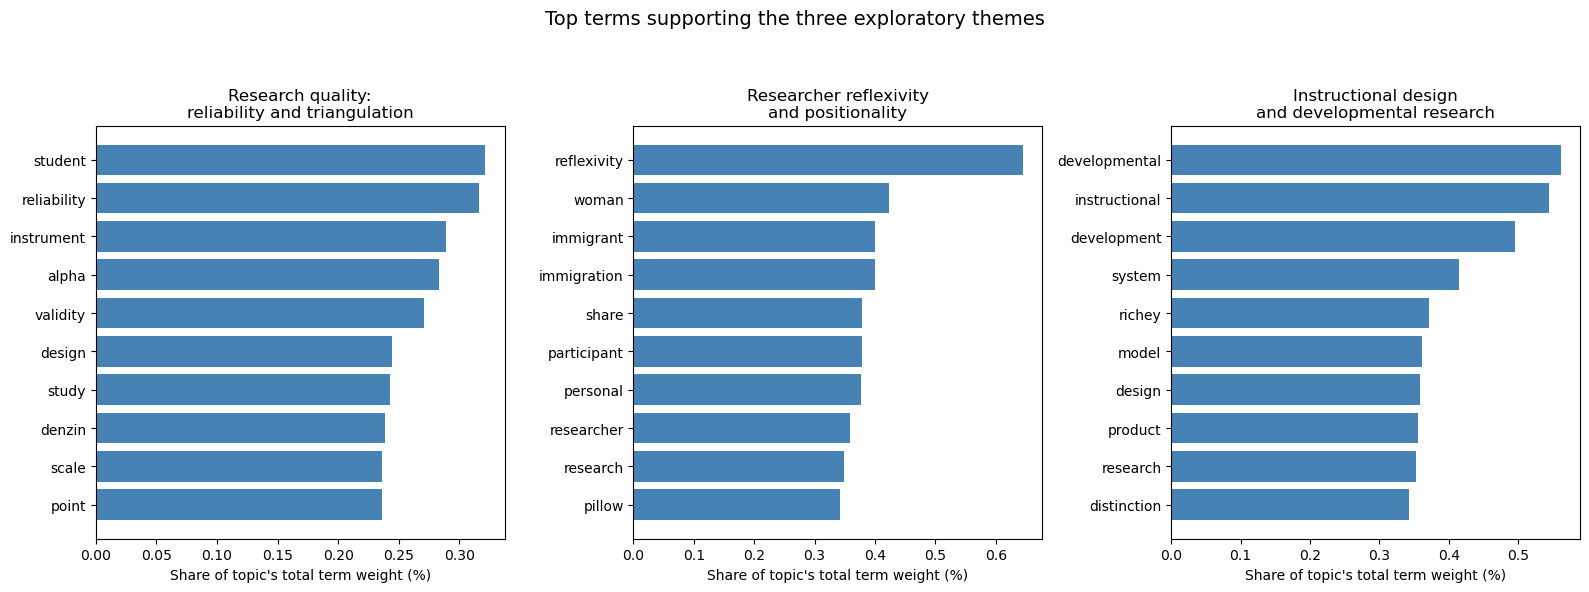

In [43]:
fig_terms, axes = plt.subplots(
    1, N_TOPICS, figsize=(16, 6)
)

for topic_index, ax in enumerate(axes):
    weights = topic_term_weights[topic_index]

    top_indices = np.argsort(weights)[-10:]

    relative_weights = weights / weights.sum()

    ax.barh(
        feature_names[top_indices],
        relative_weights[top_indices] * 100,
        color="steelblue"
    )

    ax.set_title(topic_labels[topic_index])
    ax.set_xlabel("Share of topic's total term weight (%)")

fig_terms.suptitle(
    "Top terms supporting the three exploratory themes",
    fontsize=14
)

fig_terms.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

In [44]:
topic_1_evidence = evidence_df.copy()
topic_1_evidence["topic_weight"] = evidence_topic_weights[:, 0]

article_5_evidence = topic_1_evidence.loc[
    topic_1_evidence["filename"].eq("research_5.txt")
    & ~topic_1_evidence["passage"].str.contains(
        r"keywords\s*:|corresponding author",
        case=False,
        regex=True,
        na=False
    )
].nlargest(3, "topic_weight")

print("ARTICLE 5: SUBSTANTIVE TOPIC 1 EVIDENCE")

for _, row in article_5_evidence.iterrows():
    print(
        f"\nPassage {row['sentence_number']} "
        f"| Topic weight: {row['topic_weight']:.4f}"
    )
    print(row["passage"])

print("\nCOMPLETE TOPIC TERM LISTS")

for row in topic_rows:
    print(f"\n{row['Topic']}: {row['Top terms']}")

ARTICLE 5: SUBSTANTIVE TOPIC 1 EVIDENCE

Passage 135 | Topic weight: 0.1550
A blended design is often not an option mentioned to students because of its confusion with mixed methods; however, a blended design is an excellent way to obtain rich and thick data and is occasionally the answer when students are too often discouraged from conducting phenomenological studies.

Passage 154 | Topic weight: 0.1418
For example, Patton (2002) cited Denzin and interpreted his definition of data triangulation as “the use of a variety of sources in a study” (p. 247) and methodological triangulation as “the use of multiple methods to study a single problem or program” (p. 247).

Passage 29 | Topic weight: 0.1411
Qualitative Research and Triangulation The application of triangulation (multiple sources of data) can enhance the reliability of the study results (Stavros & Westberg, 2009) and enable one to saturate the data (P. Fusch & Ness, 2015).

COMPLETE TOPIC TERM LISTS

Topic 1: student, reliability,

In [45]:
import re

header_pattern = re.compile(
    r"\bFusch,\s*Fusch,\s*&\s*Ness,\s*2018\s+"
    r"Journal\s+of\s+Social\s+Change\s+\d+\b",
    flags=re.IGNORECASE
)

header_counts = (
    remaining_df["modelling_content"]
    .apply(lambda text: len(header_pattern.findall(text)))
)

print("IDENTIFIED PAGE HEADERS REMOVED")
display(
    pd.DataFrame({
        "filename": remaining_df["filename"],
        "headers_removed": header_counts
    })
)

remaining_df["modelling_content"] = (
    remaining_df["modelling_content"]
    .apply(lambda text: header_pattern.sub(" ", text))
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

remaining_docs = list(
    nlp.pipe(remaining_df["modelling_content"], batch_size=4)
)

remaining_df["aggregate_tokens"] = [
    get_topic_tokens(doc) for doc in remaining_docs
]

remaining_df["aggregate_topic_text"] = (
    remaining_df["aggregate_tokens"].apply(" ".join)
)

remaining_df["aggregate_token_count"] = (
    remaining_df["aggregate_tokens"].str.len()
)

aggregate_matrix = aggregate_vectorizer.fit_transform(
    remaining_df["aggregate_topic_text"]
)

print("\nUpdated document–term matrix:", aggregate_matrix.shape)

IDENTIFIED PAGE HEADERS REMOVED


,filename,headers_removed
0,research_2.txt,0
1,research_3.txt,0
2,research_4.txt,0
3,research_5.txt,0



Updated document–term matrix: (4, 1943)


In [46]:
from pathlib import Path

q3_output_folder = Path(
    "C:/Users/samir/Documents/ITNPA_Project/question3_outputs"
)
q3_output_folder.mkdir(parents=True, exist_ok=True)

fig_topics.savefig(
    q3_output_folder / "aggregate_topic_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

fig_terms.savefig(
    q3_output_folder / "aggregate_topic_terms.png",
    dpi=300,
    bbox_inches="tight"
)

pd.DataFrame(topic_rows).to_csv(
    q3_output_folder / "aggregate_topic_terms.csv",
    index=False
)

pd.DataFrame(
    relative_topic_weights * 100,
    index=remaining_df["filename"],
    columns=[
        "Research quality",
        "Reflexivity and positionality",
        "Instructional developmental research"
    ]
).to_csv(
    q3_output_folder / "aggregate_topic_contributions.csv",
    index_label="filename"
)

print("Question 3.4 charts and topic tables saved to:")
print(q3_output_folder)

Question 3.4 charts and topic tables saved to:
C:\Users\samir\Documents\ITNPA_Project\question3_outputs


Collectively, the remaining four articles were summarised with the aid of NMF-assisted thematic synthesis. This method does not involve extracting sentences from the document as in Section 3.3, but rather finds the themes across the documents and then summarizes them with passages of evidence from the sources that support those themes.

The articles were described using a 4 x 1,943 TF-IDF matrix.A TF-IDF matrix with 4 articles and 1,943 term features was used to describe the articles. The three components of NMF were used as an exploratory compression for the small collection. The creation of topic labels was based on the inspection of highly weighted terms and representative passages, and the model did not create the labels or the written synthesis.

These four modelling documents did not contain any repeated passages of sentences. Seven embedded journal headers were identified during subsequent evidence inspection in article 5. These were stripped out prior to the regeneration of the features and refitting of NMF.

#### Aggregate summary

A common theme throughout the four articles is the question of how research can be designed and the results interpreted in a rigorous way. This is a concern that is tackled in the collection through the use of researcher reflexivity, systematic instructional development, measurement reliability, and triangulation.

Article 2 discusses the role of the researcher and how his or her identity, experience and relationship with participants can affect the qualitative inquiry. Rather than complete detachment it is important to consider these influences, which is the reflexivity. Research journals, peer review, participation and documenting research decisions are discussed practices. The following is a shortened version of the article provided.

According to Article 3, developmental research is systematic investigation of ID, ID development and evaluation. It distinguishes research on specific products or programmes from the investigation of processes, tools or models. This bridges development and production of knowledge related to the design and assessment of instructional interventions.

Article 4 is on the interpretation of Cronbach's α in research reporting. It emphasizes the need to interpret the meaning of a reported coefficient in the context of more than just a numerical cut-off. Attention must be paid to the instrument, the administration of the instrument, and the interpretation of the reliability or internal consistency.

Article 5 discusses triangulation with several datasets and methods and explores the differences in triangulation definition. It stresses the careful handling of methodological terms and referring to the original sources. Triangulation and Cronbach's alpha are two different answers to different questions in methodology, and should not be regarded as some sort of interchangeable measure of quality.

The collection as a whole conveys a sense of research quality in multiple dimensions. It relies on researchers being mindful of their influence; designing and evaluating a system; interpreting measurement evidence; and using multiple sources of measurement or methods with clearly justified use.

Interpretation of the topic visualisations

Document–topic heatmap illustrates the relative importance of each component in the reconstructed TF-IDF representation of the model:

Article | Main modelled theme | Relative contribution |
|---|---|---:|
Researcher reflexivity and positionality, research_2.txt | 100.0% |
Instr_Devel research | Instructional design and developmental research | 100.0% |
Research quality: reliability and triangulation | `research_4.txt` | 98.6% |
Research quality: reliability and triangulation | research_5.txt | 91.6% |

The developmental-research component adds 1.4% to the contribution of the article 4. Article 5 has an 8.4% contribution from the reflexivity component.

These percentages are model based, and not based on words or percentages of an article. The percentages of 100.0% do not mean that an article is devoted exclusively to one topic.

The term-weight charts aid interpretation of the components. The broad theme of the research quality is extended by terms such as “alpha”, “instrument”, “reliability” and “validity”. Supporting the second theme are the terms “reflexivity”, “participant”, “personal” and “researcher”; and supporting the third are the terms “developmental”, “instructional”, “design” and “product”.

The overarching component in Topic 1 is measurement reliability and triangulation. The written summary therefore retains their differences rather than taking it upon itself to assume that the model has found a single homogeneous subject.

#### Limitations

There were only 4 documents that were modelled and the number of topics was not determined as optimal. The structure of the topics can vary depending on the type of pre-processing or number of components or new documents.

Names of authors, citations and some extraction artifacts are still there. To ensure that a high topic weight is not applied to a keyword list or headings without summary text, representative passages needed to be inspected.

The second article is only partially displayed. Moreover, the provided corpus is for research methodology instead of AI publications mentioned in the assignment scenario. The findings are, therefore, only descriptive of the provided collection and cannot be used to establish trends in AI research or changes over time.

# Question 4: LDA topic modelling and project submission


## 4.1 Latent Dirichlet Allocation

In [47]:
import re
import pandas as pd

lda_df = (
    articles_df
    .sort_values("article_id")
    .copy()
    .reset_index(drop=True)
)

journal_header_pattern = re.compile(
    r"\bFusch,\s*Fusch,\s*&\s*Ness,\s*2018\s+"
    r"Journal\s+of\s+Social\s+Change\s+\d+\b",
    flags=re.IGNORECASE
)

lda_df["headers_removed"] = lda_df["clean_content"].apply(
    lambda text: len(journal_header_pattern.findall(text))
)

lda_df["lda_content"] = lda_df["clean_content"].apply(
    lambda text: re.sub(
        r"\s+",
        " ",
        journal_header_pattern.sub(" ", text)
    ).strip()
)

lda_initial_docs = list(
    nlp.pipe(lda_df["lda_content"], batch_size=5)
)

unique_texts = []
duplicate_counts = []

for doc in lda_initial_docs:
    seen = set()
    retained_passages = []
    duplicates = 0

    for sentence in doc.sents:
        text = sentence.text.strip()

        if not text:
            continue

        key = " ".join(text.lower().split())

        if key in seen:
            duplicates += 1
        else:
            seen.add(key)
            retained_passages.append(text)

    unique_texts.append(" ".join(retained_passages))
    duplicate_counts.append(duplicates)

lda_df["lda_content"] = unique_texts
lda_df["duplicate_passages_removed"] = duplicate_counts

lda_docs = list(
    nlp.pipe(lda_df["lda_content"], batch_size=5)
)

lda_df["lda_tokens"] = [
    get_topic_tokens(doc) for doc in lda_docs
]

lda_df["lda_text"] = lda_df["lda_tokens"].apply(" ".join)
lda_df["lda_token_count"] = lda_df["lda_tokens"].str.len()

assert len(lda_df) == 5
assert lda_df["lda_token_count"].gt(0).all()

display(
    lda_df[[
        "filename",
        "headers_removed",
        "duplicate_passages_removed",
        "lda_token_count"
    ]]
)

,filename,headers_removed,duplicate_passages_removed,lda_token_count
0,research_1.txt,0,82,1475
1,research_2.txt,0,0,1201
2,research_3.txt,0,0,1988
3,research_4.txt,0,0,3007
4,research_5.txt,7,0,2072


In [48]:
from sklearn.feature_extraction.text import CountVectorizer

lda_vectorizer = CountVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    preprocessor=None,
    lowercase=False,
    min_df=1,
    max_df=1.0
)

lda_count_matrix = lda_vectorizer.fit_transform(
    lda_df["lda_text"]
)

lda_feature_names = lda_vectorizer.get_feature_names_out()

print("Count matrix shape:", lda_count_matrix.shape)
print("Number of documents:", lda_count_matrix.shape[0])
print("Vocabulary size:", len(lda_feature_names))
print("Total retained token occurrences:", lda_count_matrix.sum())

Count matrix shape: (5, 2217)
Number of documents: 5
Vocabulary size: 2217
Total retained token occurrences: 9743


In [49]:
import numpy as np
from sklearn.decomposition import LatentDirichletAllocation

LDA_N_TOPICS = 3

lda_model = LatentDirichletAllocation(
    n_components=LDA_N_TOPICS,
    learning_method="batch",
    max_iter=100,
    random_state=42
)

lda_document_topics = lda_model.fit_transform(
    lda_count_matrix
)

lda_topic_word_probs = (
    lda_model.components_
    / lda_model.components_.sum(axis=1, keepdims=True)
)

lda_topic_names = [
    f"LDA Topic {i + 1}" for i in range(LDA_N_TOPICS)
]

print("LDA iterations completed:", lda_model.n_iter_)

assert np.allclose(lda_document_topics.sum(axis=1), 1.0)
assert np.allclose(lda_topic_word_probs.sum(axis=1), 1.0)

print("Topic distribution checks passed.")

lda_top_word_records = []

for topic_index, probabilities in enumerate(
    lda_topic_word_probs
):
    top_indices = np.argsort(probabilities)[::-1][:12]

    print(f"\n{lda_topic_names[topic_index]}")
    print(", ".join(lda_feature_names[top_indices]))

    for rank, word_index in enumerate(top_indices, start=1):
        lda_top_word_records.append({
            "Topic": lda_topic_names[topic_index],
            "Rank": rank,
            "Word": lda_feature_names[word_index],
            "Probability": probabilities[word_index]
        })

lda_top_words_df = pd.DataFrame(lda_top_word_records)

print("\nTOP WORDS AND THEIR PROBABILITIES")
display(lda_top_words_df.round(4))

lda_distribution_df = pd.DataFrame(
    lda_document_topics * 100,
    index=lda_df["filename"],
    columns=lda_topic_names
)

print("\nDOCUMENT–TOPIC DISTRIBUTIONS (%)")
display(lda_distribution_df.round(2))

LDA iterations completed: 100
Topic distribution checks passed.

LDA Topic 1
triangulation, datum, method, study, research, researcher, design, qualitative, denzin, multiple, use, source

LDA Topic 2
research, development, researcher, study, process, design, developmental, qualitative, method, not, instructional, reflexivity

LDA Topic 3
alpha, cronbach, instrument, value, report, reliability, science, scale, item, study, not, education

TOP WORDS AND THEIR PROBABILITIES


,Topic,Rank,Word,Probability
0,LDA Topic 1,1,triangulation,0.0289
1,LDA Topic 1,2,datum,0.0240
2,LDA Topic 1,3,method,0.0176
3,LDA Topic 1,4,study,0.0176
4,LDA Topic 1,5,research,0.0161
5,LDA Topic 1,6,researcher,0.0154
6,LDA Topic 1,7,design,0.0136
7,LDA Topic 1,8,qualitative,0.0126
8,LDA Topic 1,9,denzin,0.0111
9,LDA Topic 1,10,multiple,0.0094



DOCUMENT–TOPIC DISTRIBUTIONS (%)


,LDA Topic 1,LDA Topic 2,LDA Topic 3
filename,,,
research_1.txt,0.03,99.94,0.03
research_2.txt,0.03,99.94,0.03
research_3.txt,0.02,99.96,0.02
research_4.txt,0.01,0.01,99.98
research_5.txt,99.96,0.02,0.02


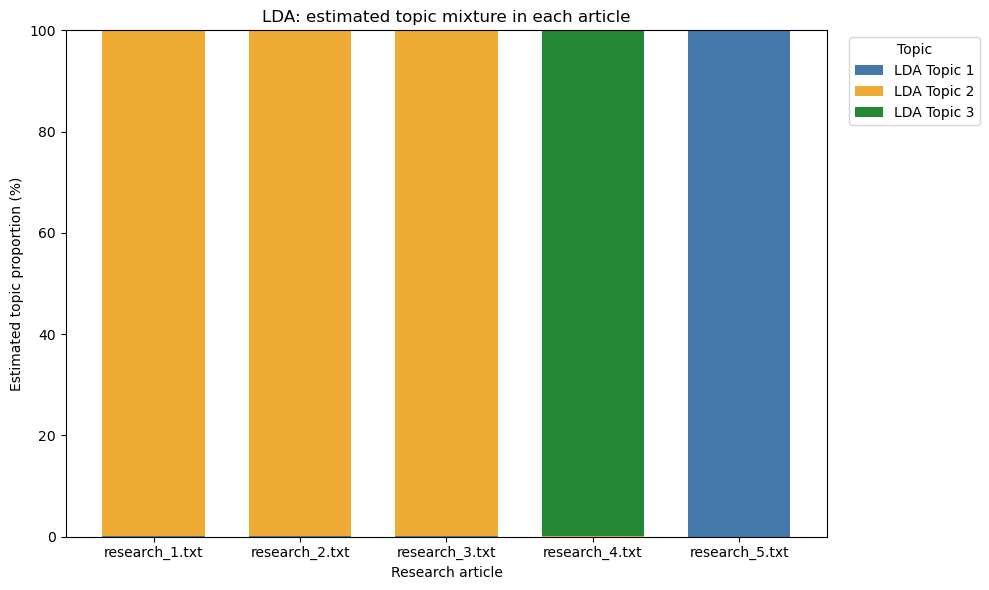

In [50]:
import matplotlib.pyplot as plt

fig_lda_distribution, ax = plt.subplots(figsize=(10, 6))

lda_distribution_df.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=["#4477AA", "#EEAA33", "#228833"],
    width=0.7
)

ax.set_title("LDA: estimated topic mixture in each article")
ax.set_xlabel("Research article")
ax.set_ylabel("Estimated topic proportion (%)")
ax.set_ylim(0, 100)

ax.tick_params(axis="x", rotation=0)
ax.legend(
    title="Topic",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

fig_lda_distribution.tight_layout()
plt.show()

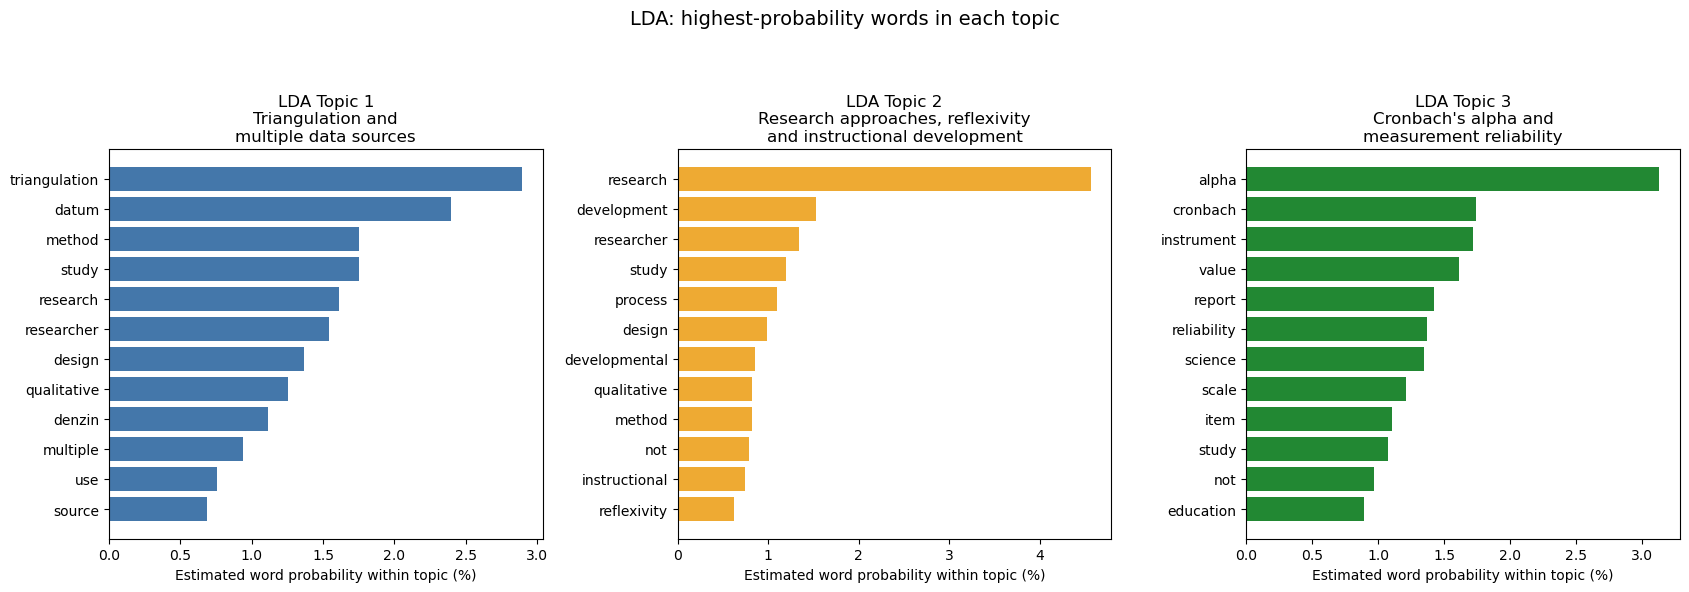

In [51]:
lda_topic_labels = [
    "Triangulation and\nmultiple data sources",
    "Research approaches, reflexivity\nand instructional development",
    "Cronbach's alpha and\nmeasurement reliability"
]

fig_lda_words, axes = plt.subplots(
    1, LDA_N_TOPICS, figsize=(17, 6)
)

topic_colours = ["#4477AA", "#EEAA33", "#228833"]

for topic_index, ax in enumerate(axes):
    probabilities = lda_topic_word_probs[topic_index]

    top_indices = np.argsort(probabilities)[-12:]

    ax.barh(
        lda_feature_names[top_indices],
        probabilities[top_indices] * 100,
        color=topic_colours[topic_index]
    )

    ax.set_title(
        f"LDA Topic {topic_index + 1}\n"
        f"{lda_topic_labels[topic_index]}"
    )

    ax.set_xlabel("Estimated word probability within topic (%)")

fig_lda_words.suptitle(
    "LDA: highest-probability words in each topic",
    fontsize=14
)

fig_lda_words.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

### LDA results and interpretation

LDA was fitted to a count matrix containing five documents and 2,217 vocabulary terms, representing 9,743 retained token occurrences. Three topics were specified, and the model completed 100 training iterations. Checks confirmed that each document–topic distribution and each topic–word distribution summed to one.

The topics were interpreted through their highest-probability words and the previously inspected article content:

- **Topic 1 — Triangulation and multiple data sources:** prominent words include “triangulation”, “datum”, “method”, “qualitative”, “Denzin” and “source”. Article 5 has an estimated 99.96% allocation to this topic.
- **Topic 2 — Research approaches, reflexivity and instructional development:** prominent words include “research”, “development”, “researcher”, “design”, “instructional” and “reflexivity”. Articles 1, 2 and 3 have estimated allocations of 99.94%, 99.94% and 99.96% respectively.
- **Topic 3 — Cronbach’s alpha and measurement reliability:** prominent words include “alpha”, “Cronbach”, “instrument”, “reliability”, “scale” and “item”. Article 4 has an estimated 99.98% allocation to this topic.

These descriptive labels were assigned through interpretation; they were not generated automatically by LDA.

### Visualisation interpretation

The stacked bar chart displays the estimated topic mixture for each article. The distributions are highly concentrated, making the small contributions from other topics almost invisible. These allocations describe the fitted model and do not establish that an article contains only one subject.

The horizontal word charts display the 12 highest-probability terms within each topic. Together, the document and word visualisations show which themes the model identifies and how those themes relate to the articles.

### Limitations

The model distinguishes the triangulation and measurement-reliability articles but combines mixed-methods research, reflexivity and instructional development into a broad second topic. This indicates limited thematic resolution under the selected three-topic configuration.

The number of topics was an exploratory choice, not a validated optimum. Completing 100 iterations does not prove convergence or topic quality. The small corpus, shared methodological vocabulary, remaining citations and the truncated second article also limit interpretation.

The near-total document allocations should not be interpreted as classification confidence. Further analysis with additional documents and alternative topic counts would be needed to assess topic stability.

In [52]:
from pathlib import Path

q4_output_folder = Path(
    "C:/Users/samir/Documents/ITNPA_Project/question4_outputs"
)
q4_output_folder.mkdir(parents=True, exist_ok=True)

fig_lda_distribution.savefig(
    q4_output_folder / "lda_document_topic_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

fig_lda_words.savefig(
    q4_output_folder / "lda_top_words.png",
    dpi=300,
    bbox_inches="tight"
)

lda_top_words_df.to_csv(
    q4_output_folder / "lda_top_words.csv",
    index=False
)

lda_distribution_df.to_csv(
    q4_output_folder / "lda_document_topic_percentages.csv",
    index_label="filename"
)

print("Question 4.1 outputs saved to:")
print(q4_output_folder)

Question 4.1 outputs saved to:
C:\Users\samir\Documents\ITNPA_Project\question4_outputs


## 4.2

In [53]:
%pip install pyLDAvis

Note: you may need to restart the kernel to use updated packages.


In [54]:
import pyLDAvis
import numpy as np
from pathlib import Path
from IPython.display import display

document_lengths = np.asarray(
    lda_count_matrix.sum(axis=1)
).ravel()

term_frequencies = np.asarray(
    lda_count_matrix.sum(axis=0)
).ravel()

# Prepare the interactive visualisation.
lda_vis = pyLDAvis.prepare(
    topic_term_dists=lda_topic_word_probs,
    doc_topic_dists=lda_document_topics,
    doc_lengths=document_lengths,
    vocab=lda_feature_names.tolist(),
    term_frequency=term_frequencies,
    R=30,
    mds="pcoa",
    sort_topics=False,
    n_jobs=1
)

q4_output_folder = Path(
    "C:/Users/samir/Documents/ITNPA_Project/question4_outputs"
)
q4_output_folder.mkdir(parents=True, exist_ok=True)

interactive_map_path = (
    q4_output_folder / "lda_interactive_map.html"
)

pyLDAvis.save_html(lda_vis, str(interactive_map_path))

print("Interactive map saved to:")
print(interactive_map_path)

display(pyLDAvis.display(lda_vis))

Interactive map saved to:
C:\Users\samir\Documents\ITNPA_Project\question4_outputs\lda_interactive_map.html


## 4.2 Interactive intertopic-distance map

### Implementation

An interactive visualisation was created using pyLDAvis and the LDA model fitted in Section 4.1. Inputs included the topic–word distributions, document–topic distributions, vocabulary, document lengths and corpus term frequencies.

Document lengths and term frequencies were calculated from the same count matrix used to fit LDA, ensuring consistent inputs. Topic sorting was disabled to preserve the topic numbering used in Section 4.1.

The visualisation was displayed in the notebook and saved as `question4_outputs/lda_interactive_map.html` for interactive inspection.

### Intertopic-distance map

Each circle represents an LDA topic. Circle area reflects estimated topic prevalence across the corpus, weighted by document token counts.

| Topic | Interpretation | Estimated corpus share |
|---|---|---:|
| 1 | Triangulation and multiple data sources | 21.3% |
| 2 | Research approaches, reflexivity and instructional development | 47.9% |
| 3 | Cronbach’s alpha and measurement reliability | 30.9% |

The percentages total 100.1% because of rounding. Topic 2 is the largest component, consistent with its strong representation across articles 1–3.

Distances between circle

In [55]:
from pathlib import Path

project_folder = Path(
    "C:/Users/samir/Documents/ITNPA_Project"
)

print("PROJECT FILE INVENTORY\n")

for path in sorted(
    project_folder.rglob("*"),
    key=lambda item: str(item).lower()
):
    relative_path = path.relative_to(project_folder)

    # Exclude automatically generated or environment folders.
    if any(
        part in {
            ".ipynb_checkpoints",
            "__pycache__",
            ".git",
            ".venv",
            "venv"
        }
        for part in relative_path.parts
    ):
        continue

    if path.is_file():
        size_kb = path.stat().st_size / 1024
        print(f"{relative_path} — {size_kb:,.1f} KB")

PROJECT FILE INVENTORY

app.py — 3.3 KB
Question1_Research_Papers.ipynb — 649.0 KB
question3_outputs\aggregate_topic_contributions.csv — 0.3 KB
question3_outputs\aggregate_topic_heatmap.png — 189.4 KB
question3_outputs\aggregate_topic_terms.csv — 0.4 KB
question3_outputs\aggregate_topic_terms.png — 247.9 KB
question3_outputs\article_1_selection_details.csv — 0.3 KB
question3_outputs\article_1_summary.txt — 1.3 KB
question3_outputs\article_1_summary_scores.png — 177.3 KB
question4_outputs\lda_document_topic_distribution.png — 105.0 KB
question4_outputs\lda_document_topic_percentages.csv — 0.4 KB
question4_outputs\lda_interactive_map.html — 25.2 KB
question4_outputs\lda_top_words.csv — 1.6 KB
question4_outputs\lda_top_words.png — 278.7 KB
research_abstracts.json — 1,347.9 KB
research_classifier.joblib — 349.1 KB
research_corpus.zip — 46.8 KB
